In [1]:
import torch
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

print("\nArecanut research environment ready!")

PyTorch: 2.15.0+cu132
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

Arecanut research environment ready!


In [2]:
from pathlib import Path

# Locate the project root
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "dataset" / "raw" / "Dataset.zip").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Project folder not found")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define dataset paths
DATASET_ROOT = PROJECT_ROOT / "dataset" / "extracted" / "Dataset"

RIPE_DIR = DATASET_ROOT / "Ripe_Input_images"
UNRIPE_DIR = DATASET_ROOT / "Un_ripe_Input_Images"

# Verify folders
print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)

print("\nRipe folder exists:", RIPE_DIR.exists())
print("Unripe folder exists:", UNRIPE_DIR.exists())

if RIPE_DIR.exists() and UNRIPE_DIR.exists():
    ripe_images = list(RIPE_DIR.glob("*"))
    unripe_images = list(UNRIPE_DIR.glob("*"))

    print("\nRipe files:", len(ripe_images))
    print("Unripe files:", len(unripe_images))
    print("Total files:", len(ripe_images) + len(unripe_images))

Project root: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter
Dataset root: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\dataset\extracted\Dataset

Ripe folder exists: True
Unripe folder exists: True

Ripe files: 388
Unripe files: 629
Total files: 1017


In [3]:

import cv2
import pandas as pd
from pathlib import Path

# Store image information
image_data = []

# Inspect both classes
for label, folder in [
    ("Ripe", RIPE_DIR),
    ("Unripe", UNRIPE_DIR)
]:

    for image_path in folder.iterdir():

        if not image_path.is_file():
            continue

        # Read image
        image = cv2.imread(str(image_path))

        # Check whether image is readable
        if image is None:
            image_data.append({
                "filename": image_path.name,
                "class": label,
                "format": image_path.suffix.lower(),
                "width": None,
                "height": None,
                "status": "Corrupted/Unreadable"
            })
            continue

        height, width = image.shape[:2]

        image_data.append({
            "filename": image_path.name,
            "class": label,
            "format": image_path.suffix.lower(),
            "width": width,
            "height": height,
            "status": "Valid"
        })

# Convert information into a DataFrame
df_images = pd.DataFrame(image_data)

# Display results
print("Total images inspected:", len(df_images))
print("\nImage formats:")
print(df_images["format"].value_counts())

print("\nImage status:")
print(df_images["status"].value_counts())

print("\nImage dimensions:")
print(df_images[["width", "height"]].describe())

print("\nFirst 10 records:")
display(df_images.head(10))


Total images inspected: 1017

Image formats:
format
.jpg    1017
Name: count, dtype: int64

Image status:
status
Valid    1017
Name: count, dtype: int64

Image dimensions:
             width       height
count  1017.000000  1017.000000
mean   4023.483776  3211.663717
std     385.403820   342.928387
min    1506.000000  1200.000000
25%    4160.000000  3120.000000
50%    4160.000000  3120.000000
75%    4160.000000  3120.000000
max    4608.000000  4160.000000

First 10 records:


,filename,class,format,width,height,status
0,0.jpg,Ripe,.jpg,3120,4160,Valid
1,1.jpg,Ripe,.jpg,4160,3120,Valid
2,10.jpg,Ripe,.jpg,4160,3120,Valid
3,100.jpg,Ripe,.jpg,3120,4160,Valid
4,101.jpg,Ripe,.jpg,4160,3120,Valid
5,102.jpg,Ripe,.jpg,4160,3120,Valid
6,103.jpg,Ripe,.jpg,4160,3120,Valid
7,104.jpg,Ripe,.jpg,3120,4160,Valid
8,105.jpg,Ripe,.jpg,4160,3120,Valid
9,106.jpg,Ripe,.jpg,4160,3120,Valid


In [4]:

import hashlib
from collections import defaultdict

# Store image hashes
hash_groups = defaultdict(list)

# Check both classes
for label, folder in [
    ("Ripe", RIPE_DIR),
    ("Unripe", UNRIPE_DIR)
]:

    for image_path in folder.iterdir():

        if not image_path.is_file():
            continue

        # Calculate SHA-256 hash
        with open(image_path, "rb") as file:
            image_hash = hashlib.sha256(file.read()).hexdigest()

        hash_groups[image_hash].append({
            "filename": image_path.name,
            "class": label,
            "path": str(image_path)
        })

# Identify duplicate groups
duplicates = {
    image_hash: files
    for image_hash, files in hash_groups.items()
    if len(files) > 1
}

print("Total unique image hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicates))

print("\nDuplicate image details:")

for image_hash, files in duplicates.items():
    print("\nHash:", image_hash[:16])

    for item in files:
        print(item["class"], "-", item["filename"])

print("\nExact duplicate copies:", 
      sum(len(files) - 1 for files in duplicates.values()))


Total unique image hashes: 744
Duplicate groups: 238

Duplicate image details:

Hash: 91016d9f8a12c565
Ripe - 0.jpg
Ripe - 153.jpg

Hash: 519dd911933c18c4
Ripe - 10.jpg
Ripe - 239.jpg

Hash: f8fa1a0d113f2224
Ripe - 102.jpg
Ripe - 229.jpg

Hash: 9c05c96d14a9ec2e
Ripe - 109.jpg
Ripe - 186.jpg

Hash: a4d31bd379c28a9f
Ripe - 11.jpg
Ripe - 257.jpg

Hash: 920e24ed363f0239
Ripe - 114.jpg
Ripe - 188.jpg

Hash: 636dda84db06112c
Ripe - 116.jpg
Ripe - 189.jpg

Hash: e2a746c32632d37b
Ripe - 119.jpg
Ripe - 190.jpg
Ripe - 230.jpg

Hash: a516909569e7ba6f
Ripe - 120.jpg
Ripe - 231.jpg

Hash: 4b24f47987a3ad7b
Ripe - 125.jpg
Ripe - 232.jpg

Hash: e26effdbd2fe7b10
Ripe - 129.jpg
Ripe - 233.jpg

Hash: 262926a070753fbd
Ripe - 13.jpg
Ripe - 240.jpg

Hash: 18a29f32614fd207
Ripe - 131.jpg
Ripe - 191.jpg
Ripe - 234.jpg

Hash: 46e761c454f1dd94
Ripe - 135.jpg
Ripe - 192.jpg
Ripe - 235.jpg

Hash: 0b15e08732e19e21
Ripe - 137.jpg
Ripe - 236.jpg

Hash: 2182a81d7ad73c7d
Ripe - 139.jpg
Ripe - 193.jpg

Hash: eb6fe87c25

In [5]:

# Find duplicate groups appearing in both classes

cross_class_duplicates = {}

for image_hash, files in hash_groups.items():

    classes = set(item["class"] for item in files)

    if len(classes) > 1:
        cross_class_duplicates[image_hash] = files

print("Cross-class duplicate groups:",
      len(cross_class_duplicates))

for image_hash, files in cross_class_duplicates.items():

    print("\nHash:", image_hash[:16])

    for item in files:
        print(item["class"], "-", item["filename"])


Cross-class duplicate groups: 46

Hash: eb6fe87c25b4faf5
Ripe - 143.jpg
Unripe - IP_UNRIP_145.jpg
Unripe - IP_UNRIP_206.jpg

Hash: cb949df60d9ae952
Ripe - 144.jpg
Unripe - IP_UNRIP_058.jpg

Hash: c9ff4c4eada3b789
Ripe - 145.jpg
Unripe - IP_UNRIP_053.jpg
Unripe - IP_UNRIP_180.jpg

Hash: dbcd488c785b041c
Ripe - 146.jpg
Unripe - IP_UNRIP_051.jpg

Hash: 0ef3f80eab2abbf6
Ripe - 147.jpg
Unripe - IP_UNRIP_041.jpg
Unripe - IP_UNRIP_175.jpg

Hash: 1c1363c820efb1b2
Ripe - 148.jpg
Ripe - 237.jpg
Ripe - 5.jpg
Unripe - IP_UNRIP_035.jpg

Hash: b37d0ded300c0892
Ripe - 149.jpg
Unripe - IP_UNRIP_030.jpg

Hash: 4da97df8457ccb21
Ripe - 150.jpg
Unripe - IP_UNRIP_005.jpg

Hash: 030df511a2bff817
Ripe - 151.jpg
Unripe - IP_UNRIP_002.jpg
Unripe - IP_UNRIP_160.jpg

Hash: c008d8129802e328
Ripe - 152.jpg
Unripe - IP_UNRIP_307.jpg

Hash: 8109a3b6fefc1eb2
Ripe - 154.jpg
Unripe - IP_UNRIP_118.jpg

Hash: c6b7f65be6638b49
Ripe - 163.jpg
Unripe - IP_UNRIP_378.jpg

Hash: 1b496a0088fc8ca0
Ripe - 164.jpg
Unripe - IP_UNRI

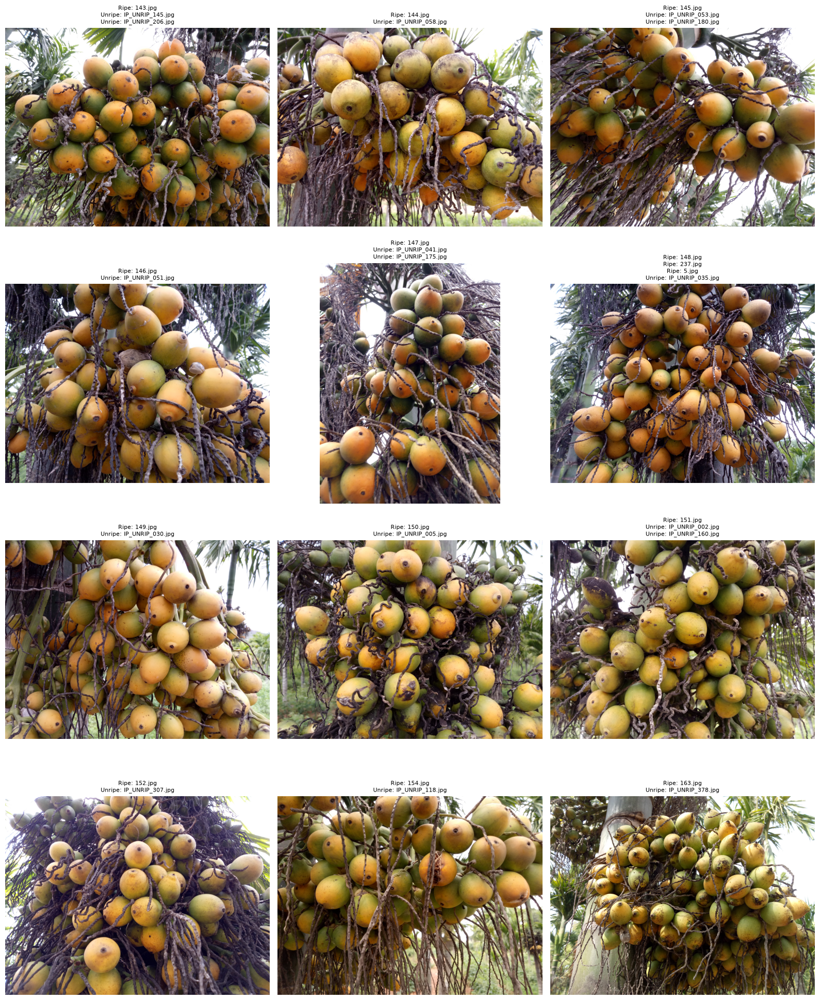

Contact sheet saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\cross_class_duplicates.png


In [6]:


import matplotlib.pyplot as plt
import cv2
from pathlib import Path

# Select 12 cross-class duplicate groups
sample_hashes = list(cross_class_duplicates.keys())[:12]

fig, axes = plt.subplots(4, 3, figsize=(16, 20))

for ax, image_hash in zip(axes.flat, sample_hashes):

    files = cross_class_duplicates[image_hash]

    # Read one representative image
    image_path = files[0]["path"]
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Display all filenames and their labels
    labels = [
        f'{item["class"]}: {item["filename"]}'
        for item in files
    ]

    ax.imshow(image)
    ax.set_title("\n".join(labels), fontsize=8)
    ax.axis("off")

plt.tight_layout()

# Save report
output_dir = PROJECT_ROOT / "research-notes" / "audit"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "cross_class_duplicates.png"

plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("Contact sheet saved:", output_path)


In [7]:

import pandas as pd

review_records = []

for image_hash, files in cross_class_duplicates.items():

    ripe_files = [
        item["filename"]
        for item in files
        if item["class"].lower() == "ripe"
    ]

    unripe_files = [
        item["filename"]
        for item in files
        if item["class"].lower() == "unripe"
    ]

    review_records.append({
        "image_hash": image_hash,
        "ripe_files": ", ".join(ripe_files),
        "unripe_files": ", ".join(unripe_files),
        "total_files": len(files),
        "review_status": "Pending",
        "final_decision": "Unresolved",
        "reason": ""
    })

review_df = pd.DataFrame(review_records)

output_dir = PROJECT_ROOT / "research-notes" / "audit"
output_dir.mkdir(parents=True, exist_ok=True)

report_path = output_dir / "cross_class_duplicate_review.csv"

review_df.to_csv(report_path, index=False)

print("Cross-class groups:", len(review_df))
print("Report saved:", report_path)

display(review_df.head(10))


Cross-class groups: 46
Report saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\cross_class_duplicate_review.csv


,image_hash,ripe_files,unripe_files,total_files,review_status,final_decision,reason
0,eb6fe87c25b4faf51b54cad72637a281aeeb7f167913ab...,143.jpg,"IP_UNRIP_145.jpg, IP_UNRIP_206.jpg",3,Pending,Unresolved,
1,cb949df60d9ae9522afc0cc6337b5a8b8929e05475cfc8...,144.jpg,IP_UNRIP_058.jpg,2,Pending,Unresolved,
2,c9ff4c4eada3b789321cdefb89c7527c80e25b4ca35de4...,145.jpg,"IP_UNRIP_053.jpg, IP_UNRIP_180.jpg",3,Pending,Unresolved,
3,dbcd488c785b041c7fdce02047f03c60a31912327048fe...,146.jpg,IP_UNRIP_051.jpg,2,Pending,Unresolved,
4,0ef3f80eab2abbf659a7237a77c60f23cf4cbbb9b084f2...,147.jpg,"IP_UNRIP_041.jpg, IP_UNRIP_175.jpg",3,Pending,Unresolved,
5,1c1363c820efb1b2eb05890ce0c89b0eaec620fc2b536c...,"148.jpg, 237.jpg, 5.jpg",IP_UNRIP_035.jpg,4,Pending,Unresolved,
6,b37d0ded300c0892929dd8b3772c6b2593ba05a964f5d7...,149.jpg,IP_UNRIP_030.jpg,2,Pending,Unresolved,
7,4da97df8457ccb21ab1493d84c2fc32ad080a20cd079cc...,150.jpg,IP_UNRIP_005.jpg,2,Pending,Unresolved,
8,030df511a2bff81707b9bebd453048f609480a025176e1...,151.jpg,"IP_UNRIP_002.jpg, IP_UNRIP_160.jpg",3,Pending,Unresolved,
9,c008d8129802e328e91510f37ca6e6a6b031f0950b27f7...,152.jpg,IP_UNRIP_307.jpg,2,Pending,Unresolved,


In [8]:

import imagehash
from PIL import Image
from itertools import combinations

# Store perceptual hashes
image_hashes = []

for folder, class_name in [
    (RIPE_DIR, "Ripe"),
    (UNRIPE_DIR, "Unripe")
]:
    for path in folder.glob("*"):
        try:
            with Image.open(path) as img:
                phash = imagehash.phash(img)

            image_hashes.append({
                "filename": path.name,
                "class": class_name,
                "path": path,
                "phash": phash
            })

        except Exception as e:
            print("Error:", path.name, e)

print("Images hashed:", len(image_hashes))



Images hashed: 1017


In [9]:

# Compare perceptual hashes across all images

near_duplicates = []

for img1, img2 in combinations(image_hashes, 2):

    distance = img1["phash"] - img2["phash"]

    if distance <= 8:
        near_duplicates.append({
            "image_1": img1["filename"],
            "class_1": img1["class"],
            "image_2": img2["filename"],
            "class_2": img2["class"],
            "hash_distance": distance,
            "path_1": str(img1["path"]),
            "path_2": str(img2["path"])
        })

near_duplicates_df = pd.DataFrame(near_duplicates)

print("Near-duplicate pairs:", len(near_duplicates_df))

if not near_duplicates_df.empty:
    display(near_duplicates_df.sort_values("hash_distance").head(30))


Near-duplicate pairs: 317


,image_1,class_1,image_2,class_2,hash_distance,path_1,path_2
314,IP_UNRIP_543.jpg,Unripe,IP_UNRIP_562.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
289,IP_UNRIP_276.jpg,Unripe,IP_UNRIP_565.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
290,IP_UNRIP_277.jpg,Unripe,IP_UNRIP_545.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
291,IP_UNRIP_277.jpg,Unripe,IP_UNRIP_572.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
292,IP_UNRIP_278.jpg,Unripe,IP_UNRIP_576.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
293,IP_UNRIP_279.jpg,Unripe,IP_UNRIP_580.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
294,IP_UNRIP_280.jpg,Unripe,IP_UNRIP_581.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
295,IP_UNRIP_281.jpg,Unripe,IP_UNRIP_586.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
296,IP_UNRIP_282.jpg,Unripe,IP_UNRIP_535.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...
297,IP_UNRIP_282.jpg,Unripe,IP_UNRIP_590.jpg,Unripe,0,c:\Users\gsama\Desktop\arecanut_research_start...,c:\Users\gsama\Desktop\arecanut_research_start...


In [10]:

# 1. Distribution of perceptual hash distances

print("HASH DISTANCE DISTRIBUTION")
print(
    near_duplicates_df["hash_distance"]
    .value_counts()
    .sort_index()
)

# 2. Separate zero-distance and non-zero pairs

zero_pairs = near_duplicates_df[
    near_duplicates_df["hash_distance"] == 0
]

nonzero_pairs = near_duplicates_df[
    near_duplicates_df["hash_distance"] > 0
]

print("\nSUMMARY")
print("Total candidate pairs:", len(near_duplicates_df))
print("Zero-distance pairs:", len(zero_pairs))
print("Non-zero-distance pairs:", len(nonzero_pairs))

# 3. Cross-class candidate pairs

cross_class_pairs = near_duplicates_df[
    near_duplicates_df["class_1"] != near_duplicates_df["class_2"]
]

print("\nCross-class candidate pairs:", len(cross_class_pairs))

# 4. Same-class candidate pairs

same_class_pairs = near_duplicates_df[
    near_duplicates_df["class_1"] == near_duplicates_df["class_2"]
]

print("Same-class candidate pairs:", len(same_class_pairs))

# 5. Save separate reports

zero_pairs.to_csv(
    output_dir / "phash_zero_distance_pairs.csv",
    index=False
)

nonzero_pairs.to_csv(
    output_dir / "phash_nonzero_distance_pairs.csv",
    index=False
)

cross_class_pairs.to_csv(
    output_dir / "phash_cross_class_pairs.csv",
    index=False
)

print("\nReports saved successfully!")


HASH DISTANCE DISTRIBUTION
hash_distance
0    315
6      1
8      1
Name: count, dtype: int64

SUMMARY
Total candidate pairs: 317
Zero-distance pairs: 315
Non-zero-distance pairs: 2

Cross-class candidate pairs: 64
Same-class candidate pairs: 253

Reports saved successfully!


In [11]:

import hashlib

# Calculate SHA-256 for every image
sha256_by_path = {}

for item in image_hashes:
    path = Path(item["path"])

    if path not in sha256_by_path:
        sha = hashlib.sha256()

        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha.update(chunk)

        sha256_by_path[path] = sha.hexdigest()


# Compare SHA-256 for every pHash candidate pair
verification_records = []

for _, row in near_duplicates_df.iterrows():

    path1 = Path(row["path_1"])
    path2 = Path(row["path_2"])

    sha1 = sha256_by_path[path1]
    sha2 = sha256_by_path[path2]

    verification_records.append({
        "image_1": row["image_1"],
        "class_1": row["class_1"],
        "image_2": row["image_2"],
        "class_2": row["class_2"],
        "phash_distance": row["hash_distance"],
        "sha256_identical": sha1 == sha2,
        "cross_class": row["class_1"] != row["class_2"]
    })

verification_df = pd.DataFrame(verification_records)

print("Total candidate pairs:", len(verification_df))
print(
    "SHA-256 identical pairs:",
    verification_df["sha256_identical"].sum()
)
print(
    "Different-file pairs:",
    (~verification_df["sha256_identical"]).sum()
)

print(
    "\nCross-class candidate pairs:",
    verification_df["cross_class"].sum()
)

print(
    "Cross-class pairs with identical SHA-256:",
    (
        verification_df["cross_class"]
        & verification_df["sha256_identical"]
    ).sum()
)

print(
    "Cross-class pairs with different SHA-256:",
    (
        verification_df["cross_class"]
        & ~verification_df["sha256_identical"]
    ).sum()
)

verification_df.to_csv(
    output_dir / "phash_sha256_verification.csv",
    index=False
)

print("\nVerification report saved.")


Total candidate pairs: 317
SHA-256 identical pairs: 311
Different-file pairs: 6

Cross-class candidate pairs: 64
Cross-class pairs with identical SHA-256: 64
Cross-class pairs with different SHA-256: 0

Verification report saved.


In [12]:
different_file_pairs = verification_df[
    verification_df["sha256_identical"] == False
]

display(
    different_file_pairs[
        [
            "image_1",
            "class_1",
            "image_2",
            "class_2",
            "phash_distance",
            "cross_class"
        ]
    ].reset_index(drop=True)
)


,image_1,class_1,image_2,class_2,phash_distance,cross_class
0,92.jpg,Ripe,98.jpg,Ripe,6,False
1,IP_UNRIP_270.jpg,Unripe,IP_UNRIP_282.jpg,Unripe,0,False
2,IP_UNRIP_270.jpg,Unripe,IP_UNRIP_590.jpg,Unripe,0,False
3,IP_UNRIP_282.jpg,Unripe,IP_UNRIP_535.jpg,Unripe,0,False
4,IP_UNRIP_323.jpg,Unripe,IP_UNRIP_325.jpg,Unripe,8,False
5,IP_UNRIP_535.jpg,Unripe,IP_UNRIP_590.jpg,Unripe,0,False


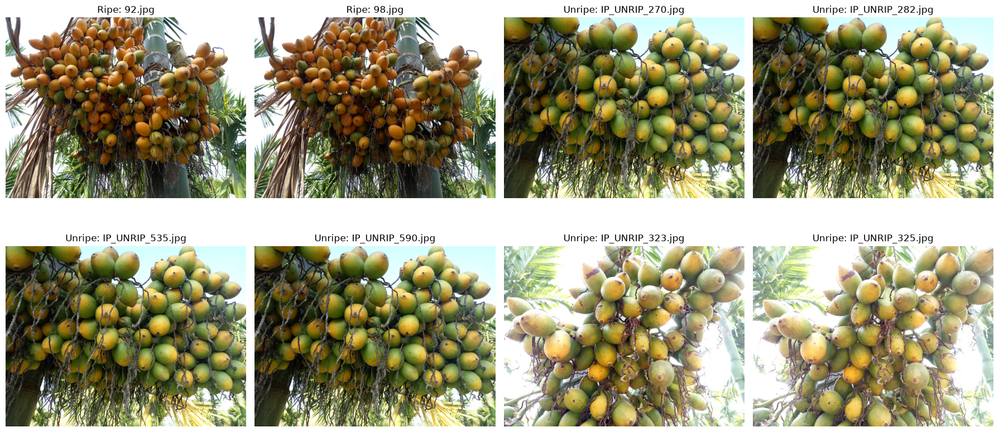

Saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\phash_different_file_review.png


In [13]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

review_files = [
    ("Ripe", "92.jpg"),
    ("Ripe", "98.jpg"),
    ("Unripe", "IP_UNRIP_270.jpg"),
    ("Unripe", "IP_UNRIP_282.jpg"),
    ("Unripe", "IP_UNRIP_535.jpg"),
    ("Unripe", "IP_UNRIP_590.jpg"),
    ("Unripe", "IP_UNRIP_323.jpg"),
    ("Unripe", "IP_UNRIP_325.jpg"),
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, (class_name, filename) in zip(axes.flat, review_files):
    folder = RIPE_DIR if class_name == "Ripe" else UNRIPE_DIR
    image_path = folder / filename

    img = Image.open(image_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{class_name}: {filename}")
    ax.axis("off")

plt.tight_layout()

contact_sheet_path = output_dir / "phash_different_file_review.png"
plt.savefig(contact_sheet_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", contact_sheet_path)

In [14]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

pairs = [
    ("Ripe", "92.jpg", "Ripe", "98.jpg"),
    ("Unripe", "IP_UNRIP_270.jpg", "Unripe", "IP_UNRIP_282.jpg"),
    ("Unripe", "IP_UNRIP_270.jpg", "Unripe", "IP_UNRIP_535.jpg"),
    ("Unripe", "IP_UNRIP_270.jpg", "Unripe", "IP_UNRIP_590.jpg"),
    ("Unripe", "IP_UNRIP_282.jpg", "Unripe", "IP_UNRIP_535.jpg"),
    ("Unripe", "IP_UNRIP_282.jpg", "Unripe", "IP_UNRIP_590.jpg"),
    ("Unripe", "IP_UNRIP_535.jpg", "Unripe", "IP_UNRIP_590.jpg"),
    ("Unripe", "IP_UNRIP_323.jpg", "Unripe", "IP_UNRIP_325.jpg"),
]

records = []

for class1, file1, class2, file2 in pairs:
    dir1 = RIPE_DIR if class1 == "Ripe" else UNRIPE_DIR
    dir2 = RIPE_DIR if class2 == "Ripe" else UNRIPE_DIR

    img1 = cv2.imread(str(dir1 / file1))
    img2 = cv2.imread(str(dir2 / file2))

    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    # Compare normalized image representations
    a = cv2.resize(img1, (256, 256))
    b = cv2.resize(img2, (256, 256))

    mae = np.mean(np.abs(
        a.astype(np.float32) - b.astype(np.float32)
    ))

    records.append({
        "image_1": file1,
        "image_2": file2,
        "dimensions_1": f"{w1}x{h1}",
        "dimensions_2": f"{w2}x{h2}",
        "same_dimensions": (w1 == w2 and h1 == h2),
        "normalized_MAE": round(float(mae), 3)
    })

comparison_df = pd.DataFrame(records)
display(comparison_df)

comparison_df.to_csv(
    output_dir / "near_duplicate_visual_comparison.csv",
    index=False
)

,image_1,image_2,dimensions_1,dimensions_2,same_dimensions,normalized_MAE
0,92.jpg,98.jpg,4160x3120,4160x3120,True,47.246
1,IP_UNRIP_270.jpg,IP_UNRIP_282.jpg,4160x3120,4160x3120,True,0.000
2,IP_UNRIP_270.jpg,IP_UNRIP_535.jpg,4160x3120,4160x3120,True,0.000
3,IP_UNRIP_270.jpg,IP_UNRIP_590.jpg,4160x3120,4160x3120,True,0.000
4,IP_UNRIP_282.jpg,IP_UNRIP_535.jpg,4160x3120,4160x3120,True,0.000
5,IP_UNRIP_282.jpg,IP_UNRIP_590.jpg,4160x3120,4160x3120,True,0.000
6,IP_UNRIP_535.jpg,IP_UNRIP_590.jpg,4160x3120,4160x3120,True,0.000
7,IP_UNRIP_323.jpg,IP_UNRIP_325.jpg,4160x3120,4160x3120,True,39.129


In [15]:
import cv2
import numpy as np
from pathlib import Path

files = [
    "IP_UNRIP_270.jpg",
    "IP_UNRIP_282.jpg",
    "IP_UNRIP_535.jpg",
    "IP_UNRIP_590.jpg"
]

images = {
    name: cv2.imread(str(UNRIPE_DIR / name))
    for name in files
}

records = []

for i in range(len(files)):
    for j in range(i + 1, len(files)):
        name1, name2 = files[i], files[j]
        img1, img2 = images[name1], images[name2]

        pixel_identical = np.array_equal(img1, img2)

        diff = cv2.absdiff(img1, img2)

        records.append({
            "image_1": name1,
            "image_2": name2,
            "same_shape": img1.shape == img2.shape,
            "full_resolution_pixel_identical": pixel_identical,
            "different_pixel_count": int(np.count_nonzero(diff)),
            "maximum_pixel_difference": int(diff.max()),
            "mean_absolute_error": float(diff.mean())
        })

full_resolution_df = pd.DataFrame(records)
display(full_resolution_df)

full_resolution_df.to_csv(
    output_dir / "full_resolution_duplicate_verification.csv",
    index=False
)

,image_1,image_2,same_shape,full_resolution_pixel_identical,different_pixel_count,maximum_pixel_difference,mean_absolute_error
0,IP_UNRIP_270.jpg,IP_UNRIP_282.jpg,True,True,0,0,0.0
1,IP_UNRIP_270.jpg,IP_UNRIP_535.jpg,True,True,0,0,0.0
2,IP_UNRIP_270.jpg,IP_UNRIP_590.jpg,True,True,0,0,0.0
3,IP_UNRIP_282.jpg,IP_UNRIP_535.jpg,True,True,0,0,0.0
4,IP_UNRIP_282.jpg,IP_UNRIP_590.jpg,True,True,0,0,0.0
5,IP_UNRIP_535.jpg,IP_UNRIP_590.jpg,True,True,0,0,0.0


In [16]:
import hashlib
from collections import defaultdict
import pandas as pd
import cv2

pixel_groups = defaultdict(list)

all_dirs = {
    "Ripe": RIPE_DIR,
    "Unripe": UNRIPE_DIR
}

for class_name, folder in all_dirs.items():
    for path in sorted(folder.glob("*")):

        if not path.is_file():
            continue

        img = cv2.imread(str(path))

        if img is None:
            continue

        # Hash image dimensions + decoded pixel data
        h = hashlib.sha256()
        h.update(str(img.shape).encode())
        h.update(img.tobytes())

        pixel_groups[h.hexdigest()].append({
            "filename": path.name,
            "class": class_name,
            "path": str(path)
        })

# Keep only groups containing multiple files
duplicate_records = []

for group_id, (pixel_hash, files) in enumerate(
    pixel_groups.items(), start=1
):
    if len(files) > 1:
        for item in files:
            duplicate_records.append({
                "group_id": group_id,
                "pixel_hash": pixel_hash,
                "filename": item["filename"],
                "class": item["class"],
                "path": item["path"],
                "group_size": len(files)
            })

pixel_duplicate_df = pd.DataFrame(duplicate_records)

print("Total images scanned:", sum(
    len(list(folder.glob("*"))) for folder in all_dirs.values()
))
print("Unique decoded pixel groups:", len(pixel_groups))
print("Duplicate groups:", pixel_duplicate_df["group_id"].nunique()
      if not pixel_duplicate_df.empty else 0)
print("Files belonging to duplicate groups:", len(pixel_duplicate_df))
print("Excess duplicate copies:", sum(
    len(files) - 1
    for files in pixel_groups.values()
    if len(files) > 1
))

pixel_duplicate_df.to_csv(
    output_dir / "pixel_level_duplicate_groups.csv",
    index=False
)

print("Saved pixel-level duplicate inventory.")

Total images scanned: 1017
Unique decoded pixel groups: 743
Duplicate groups: 237
Files belonging to duplicate groups: 511
Excess duplicate copies: 274
Saved pixel-level duplicate inventory.


In [17]:
import hashlib
from collections import defaultdict
import pandas as pd
import cv2

pixel_groups = defaultdict(list)

all_dirs = {
    "Ripe": RIPE_DIR,
    "Unripe": UNRIPE_DIR
}

for class_name, folder in all_dirs.items():
    for path in sorted(folder.glob("*")):

        if not path.is_file():
            continue

        img = cv2.imread(str(path))

        if img is None:
            continue

        # Hash image dimensions + decoded pixel data
        h = hashlib.sha256()
        h.update(str(img.shape).encode())
        h.update(img.tobytes())

        pixel_groups[h.hexdigest()].append({
            "filename": path.name,
            "class": class_name,
            "path": str(path)
        })

# Keep only groups containing multiple files
duplicate_records = []

for group_id, (pixel_hash, files) in enumerate(
    pixel_groups.items(), start=1
):
    if len(files) > 1:
        for item in files:
            duplicate_records.append({
                "group_id": group_id,
                "pixel_hash": pixel_hash,
                "filename": item["filename"],
                "class": item["class"],
                "path": item["path"],
                "group_size": len(files)
            })

pixel_duplicate_df = pd.DataFrame(duplicate_records)

print("Total images scanned:", sum(
    len(list(folder.glob("*"))) for folder in all_dirs.values()
))
print("Unique decoded pixel groups:", len(pixel_groups))
print("Duplicate groups:", pixel_duplicate_df["group_id"].nunique()
      if not pixel_duplicate_df.empty else 0)
print("Files belonging to duplicate groups:", len(pixel_duplicate_df))
print("Excess duplicate copies:", sum(
    len(files) - 1
    for files in pixel_groups.values()
    if len(files) > 1
))

pixel_duplicate_df.to_csv(
    output_dir / "pixel_level_duplicate_groups.csv",
    index=False
)

print("Saved pixel-level duplicate inventory.")

Total images scanned: 1017
Unique decoded pixel groups: 743
Duplicate groups: 237
Files belonging to duplicate groups: 511
Excess duplicate copies: 274
Saved pixel-level duplicate inventory.


In [18]:
group_summary = (
    pixel_duplicate_df
    .groupby("group_id")
    .agg(
        total_files=("filename", "count"),
        classes=("class", lambda x: sorted(set(x))),
        filenames=("filename", lambda x: list(x))
    )
    .reset_index()
)

group_summary["cross_class"] = group_summary["classes"].apply(
    lambda x: len(x) > 1
)

cross_class_groups = group_summary[
    group_summary["cross_class"]
].copy()

print("Total duplicate groups:", len(group_summary))
print("Cross-class duplicate groups:", len(cross_class_groups))
print("Same-class duplicate groups:",
      len(group_summary) - len(cross_class_groups))

print("\nCross-class duplicate groups:")
display(cross_class_groups)

cross_class_groups.to_csv(
    output_dir / "cross_class_pixel_duplicate_groups.csv",
    index=False
)

Total duplicate groups: 237
Cross-class duplicate groups: 46
Same-class duplicate groups: 191

Cross-class duplicate groups:


,group_id,total_files,classes,filenames,cross_class
16,51,3,"[Ripe, Unripe]","[143.jpg, IP_UNRIP_145.jpg, IP_UNRIP_206.jpg]",True
17,52,2,"[Ripe, Unripe]","[144.jpg, IP_UNRIP_058.jpg]",True
18,53,3,"[Ripe, Unripe]","[145.jpg, IP_UNRIP_053.jpg, IP_UNRIP_180.jpg]",True
19,54,2,"[Ripe, Unripe]","[146.jpg, IP_UNRIP_051.jpg]",True
20,55,3,"[Ripe, Unripe]","[147.jpg, IP_UNRIP_041.jpg, IP_UNRIP_175.jpg]",True
21,56,4,"[Ripe, Unripe]","[148.jpg, 237.jpg, 5.jpg, IP_UNRIP_035.jpg]",True
22,57,2,"[Ripe, Unripe]","[149.jpg, IP_UNRIP_030.jpg]",True
24,59,2,"[Ripe, Unripe]","[150.jpg, IP_UNRIP_005.jpg]",True
25,60,3,"[Ripe, Unripe]","[151.jpg, IP_UNRIP_002.jpg, IP_UNRIP_160.jpg]",True
26,61,2,"[Ripe, Unripe]","[152.jpg, IP_UNRIP_307.jpg]",True


In [19]:
cross_class_review = cross_class_groups.copy()

cross_class_review["review_status"] = "Pending"
cross_class_review["final_decision"] = "Unresolved"
cross_class_review["evidence"] = ""
cross_class_review["reviewer_notes"] = ""

cross_class_review = cross_class_review[
    [
        "group_id",
        "total_files",
        "classes",
        "filenames",
        "review_status",
        "final_decision",
        "evidence",
        "reviewer_notes"
    ]
]

review_path = (
    output_dir / "cross_class_label_conflict_review.csv"
)

cross_class_review.to_csv(review_path, index=False)

print("Cross-class groups prepared:",
      len(cross_class_review))
print("Review sheet saved:", review_path)

display(cross_class_review.head(10))

Cross-class groups prepared: 46
Review sheet saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\cross_class_label_conflict_review.csv


,group_id,total_files,classes,filenames,review_status,final_decision,evidence,reviewer_notes
16,51,3,"[Ripe, Unripe]","[143.jpg, IP_UNRIP_145.jpg, IP_UNRIP_206.jpg]",Pending,Unresolved,,
17,52,2,"[Ripe, Unripe]","[144.jpg, IP_UNRIP_058.jpg]",Pending,Unresolved,,
18,53,3,"[Ripe, Unripe]","[145.jpg, IP_UNRIP_053.jpg, IP_UNRIP_180.jpg]",Pending,Unresolved,,
19,54,2,"[Ripe, Unripe]","[146.jpg, IP_UNRIP_051.jpg]",Pending,Unresolved,,
20,55,3,"[Ripe, Unripe]","[147.jpg, IP_UNRIP_041.jpg, IP_UNRIP_175.jpg]",Pending,Unresolved,,
21,56,4,"[Ripe, Unripe]","[148.jpg, 237.jpg, 5.jpg, IP_UNRIP_035.jpg]",Pending,Unresolved,,
22,57,2,"[Ripe, Unripe]","[149.jpg, IP_UNRIP_030.jpg]",Pending,Unresolved,,
24,59,2,"[Ripe, Unripe]","[150.jpg, IP_UNRIP_005.jpg]",Pending,Unresolved,,
25,60,3,"[Ripe, Unripe]","[151.jpg, IP_UNRIP_002.jpg, IP_UNRIP_160.jpg]",Pending,Unresolved,,
26,61,2,"[Ripe, Unripe]","[152.jpg, IP_UNRIP_307.jpg]",Pending,Unresolved,,


In [20]:
print(review_path)
print("File exists:", review_path.exists())
print("File name:", review_path.name)

c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\cross_class_label_conflict_review.csv
File exists: True
File name: cross_class_label_conflict_review.csv


In [21]:
import pandas as pd
from pathlib import Path

manifest_records = []
group_counter = 0

for pixel_hash, files in pixel_groups.items():
    group_counter += 1

    files_sorted = sorted(
        files,
        key=lambda x: (x["class"], x["filename"])
    )

    classes = sorted(set(item["class"] for item in files_sorted))
    group_size = len(files_sorted)

    # Case 1: Same image content exists under conflicting labels
    if len(classes) > 1:
        for item in files_sorted:
            manifest_records.append({
                "group_id": group_counter,
                "filename": item["filename"],
                "class": item["class"],
                "path": item["path"],
                "group_size": group_size,
                "action": "QUARANTINE_LABEL_CONFLICT",
                "representative": False,
                "pixel_hash": pixel_hash
            })

    # Case 2: Same-class duplicates
    elif group_size > 1:
        representative = files_sorted[0]

        for item in files_sorted:
            is_representative = (
                item["path"] == representative["path"]
            )

            manifest_records.append({
                "group_id": group_counter,
                "filename": item["filename"],
                "class": item["class"],
                "path": item["path"],
                "group_size": group_size,
                "action": (
                    "KEEP" if is_representative
                    else "DUPLICATE_COPY"
                ),
                "representative": is_representative,
                "pixel_hash": pixel_hash
            })

    # Case 3: Unique image
    else:
        item = files_sorted[0]

        manifest_records.append({
            "group_id": group_counter,
            "filename": item["filename"],
            "class": item["class"],
            "path": item["path"],
            "group_size": 1,
            "action": "KEEP",
            "representative": True,
            "pixel_hash": pixel_hash
        })

manifest_df = pd.DataFrame(manifest_records)

# Save the complete inventory
manifest_path = output_dir / "provisional_dataset_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

# Create separate review files
quarantine_df = manifest_df[
    manifest_df["action"] == "QUARANTINE_LABEL_CONFLICT"
].copy()

duplicate_copies_df = manifest_df[
    manifest_df["action"] == "DUPLICATE_COPY"
].copy()

keep_df = manifest_df[
    manifest_df["action"] == "KEEP"
].copy()

quarantine_df.to_csv(
    output_dir / "quarantine_label_conflicts.csv",
    index=False
)

duplicate_copies_df.to_csv(
    output_dir / "same_class_duplicate_copies.csv",
    index=False
)

keep_df.to_csv(
    output_dir / "provisional_keep_manifest.csv",
    index=False
)

# Summary
print("TOTAL IMAGES:", len(manifest_df))
print("KEEP:", len(keep_df))
print("DUPLICATE COPIES:", len(duplicate_copies_df))
print("QUARANTINED:", len(quarantine_df))

print("\nPROVISIONAL RETAINED CLASS COUNTS:")
print(keep_df["class"].value_counts())

print("\nFILES SAVED:")
print(manifest_path)
print("Quarantine:", output_dir / "quarantine_label_conflicts.csv")
print("Duplicates:", output_dir / "same_class_duplicate_copies.csv")
print("Keep manifest:", output_dir / "provisional_keep_manifest.csv")

TOTAL IMAGES: 1017
KEEP: 697
DUPLICATE COPIES: 210
QUARANTINED: 110

PROVISIONAL RETAINED CLASS COUNTS:
class
Unripe    442
Ripe      255
Name: count, dtype: int64

FILES SAVED:
c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\provisional_dataset_manifest.csv
Quarantine: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\quarantine_label_conflicts.csv
Duplicates: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\same_class_duplicate_copies.csv
Keep manifest: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\provisional_keep_manifest.csv


In [22]:
print("Manifest rows:", len(manifest_df))
print("Unique file paths:", manifest_df["path"].nunique())
print("Duplicate paths:", manifest_df["path"].duplicated().sum())

print("\nAction distribution:")
print(manifest_df["action"].value_counts())

print("\nClass distribution by action:")
display(pd.crosstab(manifest_df["action"], manifest_df["class"]))

Manifest rows: 1017
Unique file paths: 1017
Duplicate paths: 0

Action distribution:
action
KEEP                         697
DUPLICATE_COPY               210
QUARANTINE_LABEL_CONFLICT    110
Name: count, dtype: int64

Class distribution by action:


class,Ripe,Unripe
action,,
DUPLICATE_COPY,83,127
KEEP,255,442
QUARANTINE_LABEL_CONFLICT,50,60


In [23]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

quality_records = []

for _, row in tqdm(keep_df.iterrows(), total=len(keep_df)):

    image_path = Path(row["path"])
    img = cv2.imread(str(image_path))

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Blur detection
    blur_score = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    # Brightness and contrast
    brightness = gray.mean()
    contrast = gray.std()

    # Exposure analysis
    dark_pixels = np.mean(gray <= 10) * 100
    bright_pixels = np.mean(gray >= 245) * 100

    quality_records.append({
        "filename": row["filename"],
        "class": row["class"],
        "path": str(image_path),
        "blur_score": blur_score,
        "brightness": brightness,
        "contrast": contrast,
        "dark_pixel_percentage": dark_pixels,
        "bright_pixel_percentage": bright_pixels
    })

quality_df = pd.DataFrame(quality_records)

quality_path = output_dir / "image_quality_audit.csv"
quality_df.to_csv(quality_path, index=False)

print("Images analyzed:", len(quality_df))
print("Quality report saved:", quality_path)

display(
    quality_df[
        [
            "blur_score",
            "brightness",
            "contrast",
            "dark_pixel_percentage",
            "bright_pixel_percentage"
        ]
    ].describe().round(2)
)


100%|██████████| 697/697 [02:19<00:00,  4.99it/s]

Images analyzed: 697
Quality report saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\image_quality_audit.csv


,blur_score,brightness,contrast,dark_pixel_percentage,bright_pixel_percentage
count,697.00,697.00,697.00,697.00,697.00
mean,238.33,107.66,70.25,2.36,8.83
std,122.71,13.50,7.62,1.40,5.26
min,41.62,57.36,51.08,0.00,0.09
25%,152.49,100.68,64.76,1.51,4.76
50%,209.07,106.98,69.81,2.12,7.99
75%,297.84,113.05,75.43,2.93,12.54
max,834.66,179.70,97.10,11.87,28.03


In [25]:
metrics = [
    "blur_score",
    "brightness",
    "contrast",
    "dark_pixel_percentage",
    "bright_pixel_percentage"
]

class_comparison = (
    quality_df
    .groupby("class")[metrics]
    .median()
    .round(2)
)

display(class_comparison)

,blur_score,brightness,contrast,dark_pixel_percentage,bright_pixel_percentage
class,,,,,
Ripe,211.74,106.16,68.95,2.33,6.98
Unripe,208.48,107.49,70.21,2.04,8.69


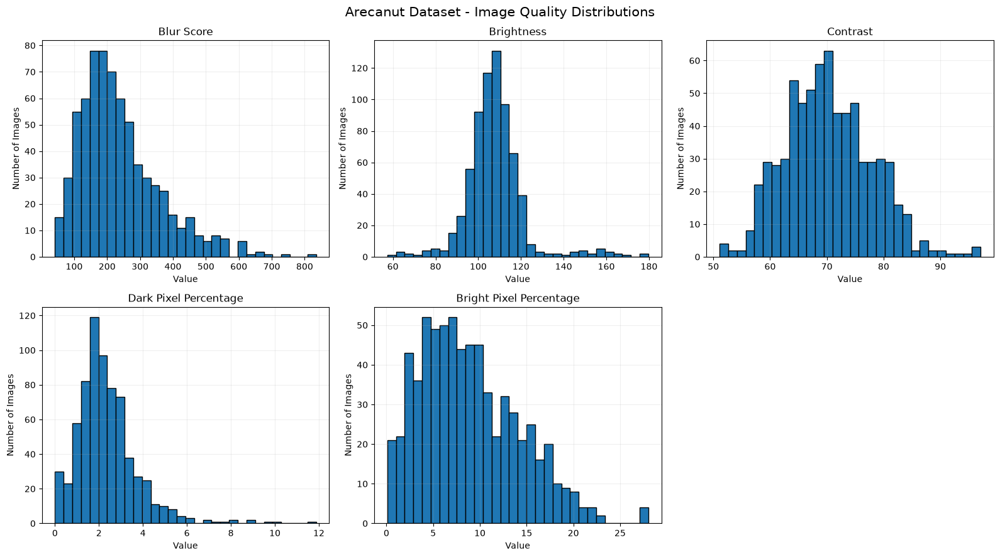

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    axes[i].hist(
        quality_df[metric],
        bins=30,
        edgecolor="black"
    )

    axes[i].set_title(metric.replace("_", " ").title())
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Number of Images")
    axes[i].grid(alpha=0.2)

axes[-1].axis("off")

plt.suptitle(
    "Arecanut Dataset - Image Quality Distributions",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [27]:
metrics = [
    "blur_score",
    "brightness",
    "contrast",
    "dark_pixel_percentage",
    "bright_pixel_percentage"
]

class_comparison = (
    quality_df
    .groupby("class")[metrics]
    .median()
    .round(2)
)

display(class_comparison)

,blur_score,brightness,contrast,dark_pixel_percentage,bright_pixel_percentage
class,,,,,
Ripe,211.74,106.16,68.95,2.33,6.98
Unripe,208.48,107.49,70.21,2.04,8.69


In [28]:
quality_df.sort_values(
    "blur_score"
).head(10)[
    ["filename", "class", "blur_score", "path"]
]

,filename,class,blur_score,path
125,282.jpg,Ripe,41.617356,c:\Users\gsama\Desktop\arecanut_research_start...
210,4.jpg,Ripe,44.509713,c:\Users\gsama\Desktop\arecanut_research_start...
246,9.jpg,Ripe,45.782901,c:\Users\gsama\Desktop\arecanut_research_start...
145,303.jpg,Ripe,46.037725,c:\Users\gsama\Desktop\arecanut_research_start...
240,81.jpg,Ripe,48.673872,c:\Users\gsama\Desktop\arecanut_research_start...
302,IP_UNRIP_054.jpg,Unripe,50.962617,c:\Users\gsama\Desktop\arecanut_research_start...
632,IP_UNRIP_526.jpg,Unripe,51.825037,c:\Users\gsama\Desktop\arecanut_research_start...
657,IP_UNRIP_566.jpg,Unripe,53.080838,c:\Users\gsama\Desktop\arecanut_research_start...
398,IP_UNRIP_159.jpg,Unripe,56.333486,c:\Users\gsama\Desktop\arecanut_research_start...
343,IP_UNRIP_100.jpg,Unripe,56.746868,c:\Users\gsama\Desktop\arecanut_research_start...


In [29]:
quality_df.sort_values(
    "bright_pixel_percentage",
    ascending=False
).head(10)[
    ["filename", "class", "bright_pixel_percentage", "path"]
]

,filename,class,bright_pixel_percentage,path
553,IP_UNRIP_410.jpg,Unripe,28.025063,c:\Users\gsama\Desktop\arecanut_research_start...
537,IP_UNRIP_389.jpg,Unripe,27.785041,c:\Users\gsama\Desktop\arecanut_research_start...
686,IP_UNRIP_609.jpg,Unripe,27.713680,c:\Users\gsama\Desktop\arecanut_research_start...
623,IP_UNRIP_513.jpg,Unripe,27.441283,c:\Users\gsama\Desktop\arecanut_research_start...
551,IP_UNRIP_408.jpg,Unripe,23.055011,c:\Users\gsama\Desktop\arecanut_research_start...
643,IP_UNRIP_544.jpg,Unripe,22.583256,c:\Users\gsama\Desktop\arecanut_research_start...
542,IP_UNRIP_395.jpg,Unripe,22.148777,c:\Users\gsama\Desktop\arecanut_research_start...
125,282.jpg,Ripe,22.100780,c:\Users\gsama\Desktop\arecanut_research_start...
400,IP_UNRIP_209.jpg,Unripe,21.981178,c:\Users\gsama\Desktop\arecanut_research_start...
167,326.jpg,Ripe,21.831315,c:\Users\gsama\Desktop\arecanut_research_start...


In [30]:
from scipy.stats import mannwhitneyu
import pandas as pd

results = []

for metric in metrics:

    ripe = quality_df.loc[
        quality_df["class"] == "Ripe", metric
    ]

    unripe = quality_df.loc[
        quality_df["class"] == "Unripe", metric
    ]

    statistic, p_value = mannwhitneyu(
        ripe,
        unripe,
        alternative="two-sided"
    )

    results.append({
        "Metric": metric,
        "Ripe Median": ripe.median(),
        "Unripe Median": unripe.median(),
        "U Statistic": statistic,
        "P Value": p_value
    })

statistical_results = pd.DataFrame(results)

display(statistical_results.round(4))

,Metric,Ripe Median,Unripe Median,U Statistic,P Value
0,blur_score,211.7436,208.4850,55376.0,0.7023
1,brightness,106.1633,107.4948,53248.0,0.2250
2,contrast,68.9463,70.2125,49563.0,0.0080
3,dark_pixel_percentage,2.3264,2.0382,61465.0,0.0460
4,bright_pixel_percentage,6.9824,8.6928,46731.0,0.0002


In [32]:
print("Available columns:")
print(statistical_results.columns.tolist())

display(
    statistical_results[
        ["Metric", "P Value", "Holm_Adjusted_P",
         "Significant_After_Correction"]
    ].round(4)
)

Available columns:
['Metric', 'Ripe Median', 'Unripe Median', 'U Statistic', 'P Value']


KeyError: "['Holm_Adjusted_P', 'Significant_After_Correction'] not in index"

In [34]:
from statsmodels.stats.multitest import multipletests

# Apply Holm-Bonferroni correction
adjusted_p = multipletests(
    statistical_results["P Value"].values,
    method="holm"
)[1]

# Add corrected values to the existing DataFrame
statistical_results["Holm_Adjusted_P"] = adjusted_p

statistical_results["Significant_After_Correction"] = (
    statistical_results["Holm_Adjusted_P"] < 0.05
)

# Display final results
display(
    statistical_results[
        [
            "Metric",
            "P Value",
            "Holm_Adjusted_P",
            "Significant_After_Correction"
        ]
    ].round(4)
)

,Metric,P Value,Holm_Adjusted_P,Significant_After_Correction
0,blur_score,0.7023,0.7023,False
1,brightness,0.2250,0.4501,False
2,contrast,0.0080,0.0320,True
3,dark_pixel_percentage,0.0460,0.1380,False
4,bright_pixel_percentage,0.0002,0.0009,True


In [35]:
n_ripe = (quality_df["class"] == "Ripe").sum()
n_unripe = (quality_df["class"] == "Unripe").sum()

statistical_results["Rank_Biserial_Effect"] = (
    2 * statistical_results["U Statistic"]
    / (n_ripe * n_unripe)
) - 1

display(
    statistical_results[
        [
            "Metric",
            "P Value",
            "Holm_Adjusted_P",
            "Rank_Biserial_Effect",
            "Significant_After_Correction"
        ]
    ].round(4)
)

,Metric,P Value,Holm_Adjusted_P,Rank_Biserial_Effect,Significant_After_Correction
0,blur_score,0.7023,0.7023,-0.0174,False
1,brightness,0.2250,0.4501,-0.0551,False
2,contrast,0.0080,0.0320,-0.1205,True
3,dark_pixel_percentage,0.0460,0.1380,0.0907,False
4,bright_pixel_percentage,0.0002,0.0009,-0.1708,True


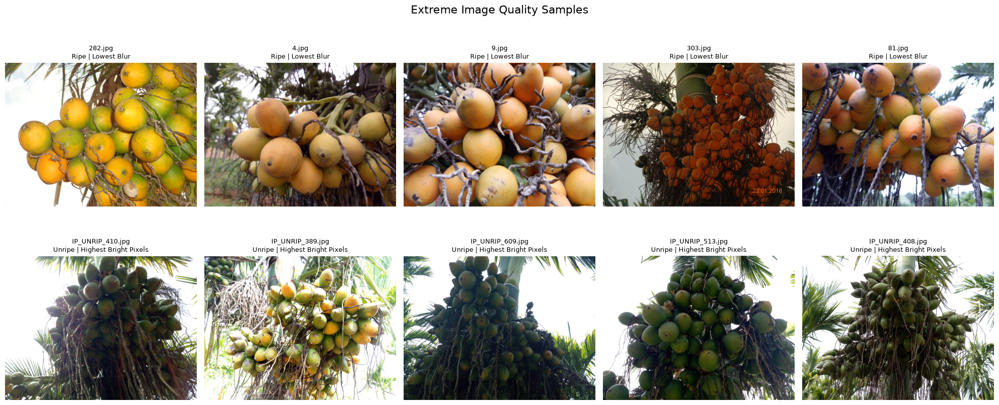

In [36]:
import matplotlib.pyplot as plt
import cv2
import math

lowest_blur = quality_df.nsmallest(5, "blur_score")

highest_bright = quality_df.nlargest(
    5, "bright_pixel_percentage"
)

samples = pd.concat([
    lowest_blur.assign(category="Lowest Blur"),
    highest_bright.assign(category="Highest Bright Pixels")
])

fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):

    img = cv2.imread(row["path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(
        f'{row["filename"]}\n'
        f'{row["class"]} | {row["category"]}',
        fontsize=9
    )
    ax.axis("off")

plt.suptitle(
    "Extreme Image Quality Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [37]:
# Check class distribution in the quality dataset
print("Class distribution:")
display(quality_df["class"].value_counts())

# Random balanced sample
random_ripe = quality_df[
    quality_df["class"] == "Ripe"
].sample(n=5, random_state=42)

random_unripe = quality_df[
    quality_df["class"] == "Unripe"
].sample(n=5, random_state=42)

# Combine representative and extreme samples
visual_review = pd.concat([
    random_ripe.assign(review_group="Random Ripe"),
    random_unripe.assign(review_group="Random Unripe"),
    quality_df.nlargest(
        5, "bright_pixel_percentage"
    ).assign(review_group="High Bright Pixels"),
    quality_df.nsmallest(
        5, "blur_score"
    ).assign(review_group="Low Blur")
])

# Save review manifest
review_path = output_dir / "visual_quality_review.csv"
visual_review.to_csv(review_path, index=False)

print("Review manifest saved:", review_path)
print("Total review entries:", len(visual_review))

Class distribution:


class
Unripe    442
Ripe      255
Name: count, dtype: int64

Review manifest saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\visual_quality_review.csv
Total review entries: 20


In [38]:
print("Review entries:", len(visual_review))
print("\nReview groups:")
display(visual_review["review_group"].value_counts())

print("\nSaved file exists:", review_path.exists())

Review entries: 20

Review groups:


review_group
Random Ripe           5
Random Unripe         5
High Bright Pixels    5
Low Blur              5
Name: count, dtype: int64


Saved file exists: True


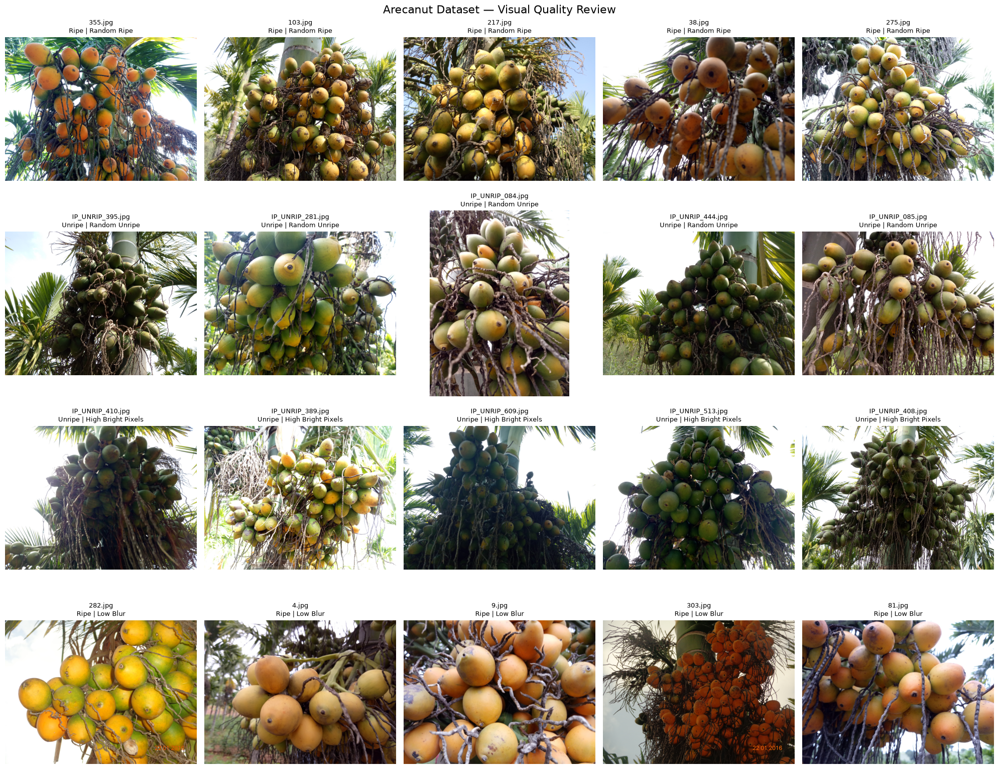

In [39]:
import matplotlib.pyplot as plt
import cv2
import math

fig, axes = plt.subplots(4, 5, figsize=(20, 16))

for ax, (_, row) in zip(axes.flatten(), visual_review.iterrows()):

    img = cv2.imread(row["path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(
        f'{row["filename"]}\n'
        f'{row["class"]} | {row["review_group"]}',
        fontsize=9
    )
    ax.axis("off")

plt.suptitle(
    "Arecanut Dataset — Visual Quality Review",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [40]:
visual_observations = pd.DataFrame([
    {
        "category": "Random Ripe",
        "observation": "Predominantly yellow, orange and orange-brown fruits with variation in camera angles, bunch density and background.",
        "decision": "Retain pending label validation"
    },
    {
        "category": "Random Unripe",
        "observation": "Predominantly green and green-yellow fruits with natural variation in illumination and fruit coloration.",
        "decision": "Retain pending label validation"
    },
    {
        "category": "High Bright Pixels",
        "observation": "Several images contain bright sky regions and backlighting. Whole-image exposure metrics may be influenced by background pixels.",
        "decision": "Retain; investigate fruit-region quality"
    },
    {
        "category": "Low Blur",
        "observation": "Some low-scoring images still show distinguishable fruit boundaries. Laplacian variance alone is insufficient for rejection.",
        "decision": "Retain; no automatic rejection"
    }
])

visual_summary_path = (
    output_dir / "visual_quality_observations.csv"
)

visual_observations.to_csv(
    visual_summary_path,
    index=False
)

print("Saved:", visual_summary_path)
display(visual_observations)

Saved: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\visual_quality_observations.csv


,category,observation,decision
0,Random Ripe,"Predominantly yellow, orange and orange-brown ...",Retain pending label validation
1,Random Unripe,Predominantly green and green-yellow fruits wi...,Retain pending label validation
2,High Bright Pixels,Several images contain bright sky regions and ...,Retain; investigate fruit-region quality
3,Low Blur,Some low-scoring images still show distinguish...,Retain; no automatic rejection


In [41]:
print("Cross-class conflict groups:", len(cross_class_groups))
print("Files involved:", sum(
    len(group["filenames"])
    for _, group in cross_class_groups.iterrows()
))

print("\nReview status:")
display(
    pd.read_csv(review_path)["review_status"].value_counts()
)

Cross-class conflict groups: 46
Files involved: 110

Review status:


KeyError: 'review_status'

In [42]:
review_df = pd.read_csv(review_path)

print("Columns:")
print(review_df.columns.tolist())

print("\nFirst five records:")
display(review_df.head())

Columns:
['filename', 'class', 'path', 'blur_score', 'brightness', 'contrast', 'dark_pixel_percentage', 'bright_pixel_percentage', 'review_group']

First five records:


,filename,class,path,blur_score,brightness,contrast,dark_pixel_percentage,bright_pixel_percentage,review_group
0,355.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,438.883030,121.363813,71.849849,1.461307,14.703634,Random Ripe
1,103.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,290.950181,114.611935,76.545848,3.147629,11.156443,Random Ripe
2,217.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,233.255364,107.971941,68.813816,2.609729,0.564311,Random Ripe
3,38.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,259.881946,100.914418,75.410486,2.466685,13.642520,Random Ripe
4,275.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,374.444099,134.371300,77.581746,1.283592,17.110908,Random Ripe


In [43]:
cross_class_review_path = (
    output_dir / "cross_class_label_conflict_review.csv"
)

print("File exists:", cross_class_review_path.exists())
print("Path:", cross_class_review_path)

File exists: True
Path: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\research-notes\audit\cross_class_label_conflict_review.csv


In [44]:
cross_class_review_df = pd.read_csv(
    cross_class_review_path
)

print("Columns:")
print(cross_class_review_df.columns.tolist())

print("\nReview status:")
display(
    cross_class_review_df["review_status"].value_counts()
)

print("\nFirst five records:")
display(cross_class_review_df.head())

Columns:
['group_id', 'total_files', 'classes', 'filenames', 'review_status', 'final_decision', 'evidence', 'reviewer_notes']

Review status:


review_status
Pending    46
Name: count, dtype: int64


First five records:


,group_id,total_files,classes,filenames,review_status,final_decision,evidence,reviewer_notes
0,51,3,"['Ripe', 'Unripe']","['143.jpg', 'IP_UNRIP_145.jpg', 'IP_UNRIP_206....",Pending,Unresolved,NaN,NaN
1,52,2,"['Ripe', 'Unripe']","['144.jpg', 'IP_UNRIP_058.jpg']",Pending,Unresolved,NaN,NaN
2,53,3,"['Ripe', 'Unripe']","['145.jpg', 'IP_UNRIP_053.jpg', 'IP_UNRIP_180....",Pending,Unresolved,NaN,NaN
3,54,2,"['Ripe', 'Unripe']","['146.jpg', 'IP_UNRIP_051.jpg']",Pending,Unresolved,NaN,NaN
4,55,3,"['Ripe', 'Unripe']","['147.jpg', 'IP_UNRIP_041.jpg', 'IP_UNRIP_175....",Pending,Unresolved,NaN,NaN


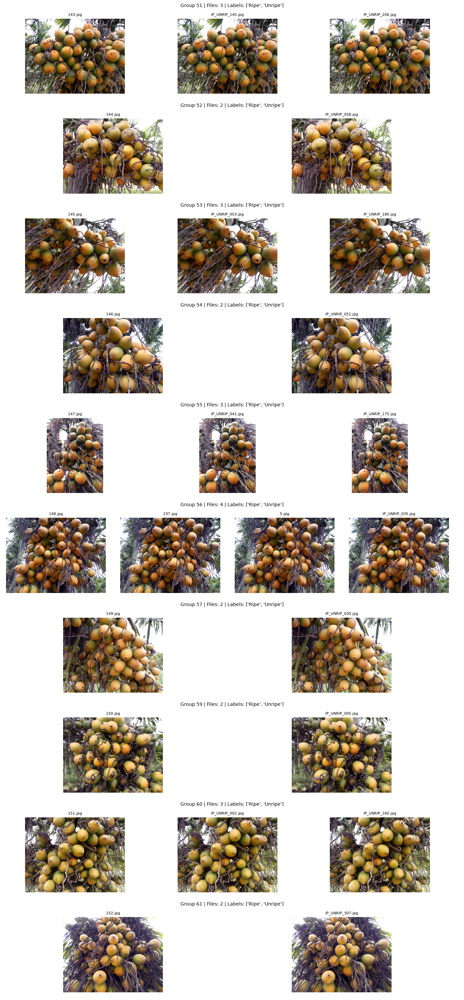

In [48]:
import ast
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

review_batch = cross_class_review_df.head(10)

fig, axes = plt.subplots(10, 1, figsize=(14, 30))

for ax, (_, row) in zip(axes, review_batch.iterrows()):

    filenames = ast.literal_eval(row["filenames"])

    ax.axis("off")
    ax.set_title(
        f'Group {row["group_id"]} | '
        f'Files: {row["total_files"]} | '
        f'Labels: {row["classes"]}',
        fontsize=10
    )

    images = []

    for filename in filenames:
        matches = manifest_df[
            manifest_df["filename"] == filename
        ]

        if matches.empty:
            continue

        image_path = matches.iloc[0]["path"]
        img = cv2.imread(str(image_path))

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            images.append((filename, img))

    # Display each group's files side by side
    for i, (filename, img) in enumerate(images):
        # Create an inset axis for each image
        inset = ax.inset_axes([
            i / len(images),
            0.05,
            1 / len(images) - 0.02,
            0.85
        ])

        inset.imshow(img)
        inset.set_title(filename, fontsize=8)
        inset.axis("off")

plt.tight_layout()
plt.show()
review_batch = cross_class_review_df.iloc[10:20]

In [46]:

review_batch = cross_class_review_df.iloc[10:20]

print("Groups to inspect:")
display(
    review_batch[
        ["group_id", "total_files", "classes", "filenames"]
    ]
)


Groups to inspect:


,group_id,total_files,classes,filenames
10,62,2,"['Ripe', 'Unripe']","['154.jpg', 'IP_UNRIP_118.jpg']"
11,72,2,"['Ripe', 'Unripe']","['163.jpg', 'IP_UNRIP_378.jpg']"
12,73,2,"['Ripe', 'Unripe']","['164.jpg', 'IP_UNRIP_383.jpg']"
13,74,3,"['Ripe', 'Unripe']","['165.jpg', 'IP_UNRIP_109.jpg', 'IP_UNRIP_200...."
14,75,3,"['Ripe', 'Unripe']","['166.jpg', 'IP_UNRIP_233.jpg', 'IP_UNRIP_388...."
15,76,2,"['Ripe', 'Unripe']","['167.jpg', 'IP_UNRIP_404.jpg']"
16,77,2,"['Ripe', 'Unripe']","['168.jpg', 'IP_UNRIP_420.jpg']"
17,78,2,"['Ripe', 'Unripe']","['169.jpg', 'IP_UNRIP_427.jpg']"
18,80,3,"['Ripe', 'Unripe']","['170.jpg', 'IP_UNRIP_246.jpg', 'IP_UNRIP_442...."
19,81,2,"['Ripe', 'Unripe']","['171.jpg', 'IP_UNRIP_452.jpg']"


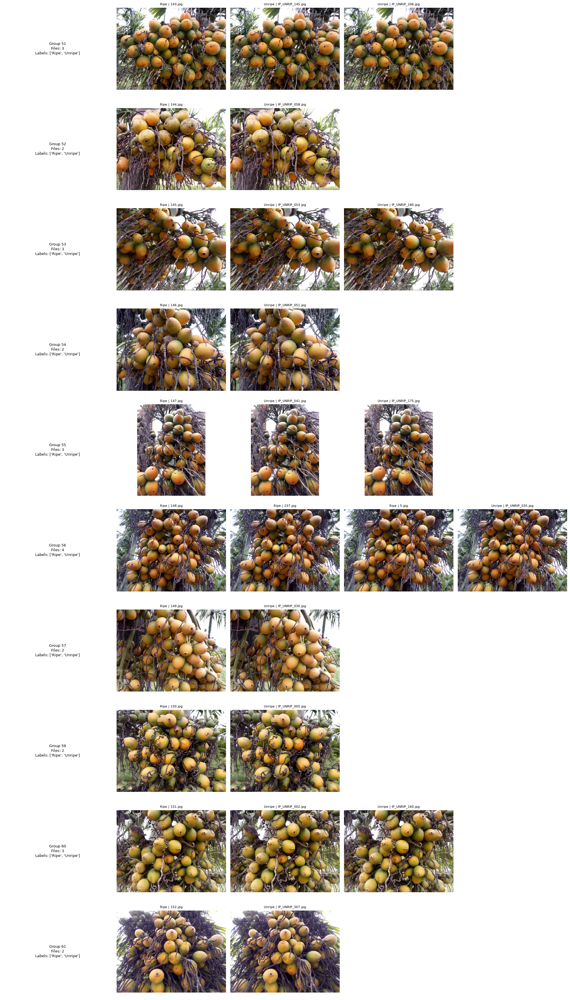

In [50]:

import ast
import cv2
import matplotlib.pyplot as plt

# Find the maximum number of images in any selected group
max_images = max(
    len(ast.literal_eval(row["filenames"]))
    for _, row in review_batch.iterrows()
)

fig, axes = plt.subplots(
    len(review_batch),
    max_images + 1,
    figsize=(4 * (max_images + 1), 3.5 * len(review_batch)),
    squeeze=False
)

for row_idx, (_, row) in enumerate(review_batch.iterrows()):

    filenames = ast.literal_eval(row["filenames"])

    # Retrieve exact group members using decoded pixel groups
    matching_group = next(
        files for files in pixel_groups.values()
        if sorted(f["filename"] for f in files) == sorted(filenames)
    )

    # Group information
    axes[row_idx, 0].text(
        0.5, 0.5,
        f"Group {row['group_id']}\n"
        f"Files: {row['total_files']}\n"
        f"Labels: {row['classes']}",
        ha="center", va="center",
        fontsize=9
    )
    axes[row_idx, 0].axis("off")

    # Display every image in the group
    for col_idx, file_info in enumerate(matching_group, start=1):

        img = cv2.imread(str(file_info["path"]))

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[row_idx, col_idx].imshow(img)

        axes[row_idx, col_idx].set_title(
            f"{file_info['class']} | {file_info['filename']}",
            fontsize=8
        )
        axes[row_idx, col_idx].axis("off")

    # Hide unused columns
    for col_idx in range(len(matching_group) + 1, max_images + 1):
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()


In [52]:
review_batch = cross_class_review_df.iloc[10:20].copy()

print("Selected group IDs:")
print(review_batch["group_id"].tolist())

print("\nExpected group IDs:")
print([62, 72, 73, 74, 75, 76, 77, 78, 80, 81])

plt.close("all")

Selected group IDs:
[62, 72, 73, 74, 75, 76, 77, 78, 80, 81]

Expected group IDs:
[62, 72, 73, 74, 75, 76, 77, 78, 80, 81]


In [53]:
for _, row in review_batch.iterrows():
    print(
        f"Group {row['group_id']}: "
        f"{ast.literal_eval(row['filenames'])}"
    )

Group 62: ['154.jpg', 'IP_UNRIP_118.jpg']
Group 72: ['163.jpg', 'IP_UNRIP_378.jpg']
Group 73: ['164.jpg', 'IP_UNRIP_383.jpg']
Group 74: ['165.jpg', 'IP_UNRIP_109.jpg', 'IP_UNRIP_200.jpg']
Group 75: ['166.jpg', 'IP_UNRIP_233.jpg', 'IP_UNRIP_388.jpg']
Group 76: ['167.jpg', 'IP_UNRIP_404.jpg']
Group 77: ['168.jpg', 'IP_UNRIP_420.jpg']
Group 78: ['169.jpg', 'IP_UNRIP_427.jpg']
Group 80: ['170.jpg', 'IP_UNRIP_246.jpg', 'IP_UNRIP_442.jpg']
Group 81: ['171.jpg', 'IP_UNRIP_452.jpg']


Rendering groups: [62, 72, 73, 74, 75, 76, 77, 78, 80, 81]


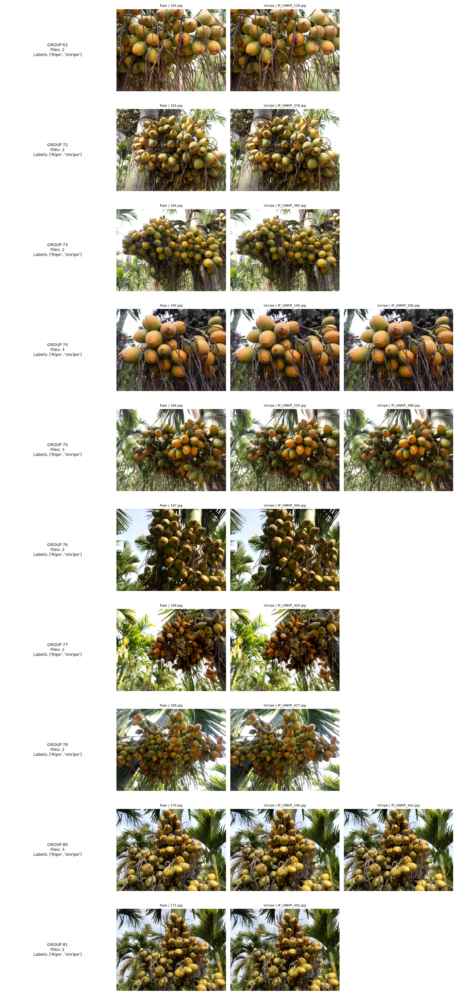

In [54]:

import ast
import cv2
import matplotlib.pyplot as plt

# Close all previous figures
plt.close("all")

# Confirm the batch before rendering
print("Rendering groups:", review_batch["group_id"].tolist())

max_images = max(
    len(ast.literal_eval(row["filenames"]))
    for _, row in review_batch.iterrows()
)

fig, axes = plt.subplots(
    len(review_batch),
    max_images + 1,
    figsize=(4 * (max_images + 1), 3.5 * len(review_batch)),
    squeeze=False
)

for row_idx, (_, row) in enumerate(review_batch.iterrows()):

    filenames = ast.literal_eval(row["filenames"])

    matching_group = next(
        files for files in pixel_groups.values()
        if sorted(f["filename"] for f in files) == sorted(filenames)
    )

    axes[row_idx, 0].text(
        0.5, 0.5,
        f"GROUP {row['group_id']}\n"
        f"Files: {row['total_files']}\n"
        f"Labels: {row['classes']}",
        ha="center", va="center", fontsize=10
    )
    axes[row_idx, 0].axis("off")

    for col_idx, file_info in enumerate(matching_group, start=1):

        img = cv2.imread(str(file_info["path"]))

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[row_idx, col_idx].imshow(img)

        axes[row_idx, col_idx].set_title(
            f"{file_info['class']} | {file_info['filename']}",
            fontsize=8
        )
        axes[row_idx, col_idx].axis("off")

    for col_idx in range(len(matching_group) + 1, max_images + 1):
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()


In [56]:

reviewed_group_ids = [62, 72, 73, 74, 75, 76, 77, 78, 80, 81]

# Ensure text columns can store strings
text_columns = [
    "review_status",
    "final_decision",
    "evidence",
    "reviewer_notes"
]

for col in text_columns:
    cross_class_review_df[col] = (
        cross_class_review_df[col].astype("string")
    )

# Select reviewed groups
mask = cross_class_review_df["group_id"].isin(reviewed_group_ids)

# Update review records
cross_class_review_df.loc[mask, "review_status"] = "Reviewed"
cross_class_review_df.loc[mask, "final_decision"] = "Quarantine"

cross_class_review_df.loc[mask, "evidence"] = (
    "Same decoded pixel content under Ripe and Unripe labels"
)

cross_class_review_df.loc[mask, "reviewer_notes"] = (
    "Visual contact sheet inspected; conflicting labels unresolved. "
    "Original files and labels preserved."
)

# Save updated register
cross_class_review_df.to_csv(cross_class_review_path, index=False)

# Verify
print("Groups updated:", mask.sum())

print("\nReview status:")
print(cross_class_review_df["review_status"].value_counts())

print("\nUpdated records:")
display(
    cross_class_review_df.loc[
        mask,
        ["group_id", "review_status", "final_decision", "evidence"]
    ]
)


Groups updated: 10

Review status:
review_status
Pending     36
Reviewed    10
Name: count, dtype: Int64

Updated records:


,group_id,review_status,final_decision,evidence
10,62,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
11,72,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
12,73,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
13,74,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
14,75,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
15,76,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
16,77,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
17,78,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
18,80,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...
19,81,Reviewed,Quarantine,Same decoded pixel content under Ripe and Unri...


In [67]:
review_batch = cross_class_review_df[
    cross_class_review_df["review_status"] == "Pending"
].head(10).copy()

print("Next groups:", review_batch["group_id"].tolist())

Next groups: [111, 112, 113, 116, 128, 134]


In [58]:
previously_reviewed_ids = [
    51, 52, 53, 54, 55, 56, 57, 59, 60, 61
]

mask = cross_class_review_df["group_id"].isin(
    previously_reviewed_ids
)

cross_class_review_df.loc[mask, "review_status"] = "Reviewed"
cross_class_review_df.loc[mask, "final_decision"] = "Quarantine"

cross_class_review_df.loc[mask, "evidence"] = (
    "Same decoded pixel content under Ripe and Unripe labels"
)

cross_class_review_df.loc[mask, "reviewer_notes"] = (
    "Previously inspected in visual contact sheet; "
    "conflicting labels unresolved. Original files preserved."
)

cross_class_review_df.to_csv(cross_class_review_path, index=False)

print("Updated:", mask.sum())
print(cross_class_review_df["review_status"].value_counts())

Updated: 10
review_status
Pending     26
Reviewed    20
Name: count, dtype: Int64


In [72]:
review_batch = cross_class_review_df[
    cross_class_review_df["review_status"] == "Pending"
].head(10).copy()

print("Next groups:", review_batch["group_id"].tolist())

display(
    review_batch[
        ["group_id", "total_files", "classes", "filenames"]
    ]
)

Next groups: []


,group_id,total_files,classes,filenames


In [71]:
print("Rendering groups:", review_batch["group_id"].tolist())

Rendering groups: [111, 112, 113, 116, 128, 134]


In [70]:

import ast
import cv2
import matplotlib.pyplot as plt

# 1. Clear previously displayed figures
plt.close("all")

# 2. Verify selected batch
print("Rendering groups:", review_batch["group_id"].tolist())

# 3. Calculate maximum images per group
max_images = max(
    len(ast.literal_eval(row["filenames"]))
    for _, row in review_batch.iterrows()
)

# 4. Create contact sheet dynamically
fig, axes = plt.subplots(
    len(review_batch),
    max_images + 1,
    figsize=(4 * (max_images + 1), 3.5 * len(review_batch)),
    squeeze=False
)

# 5. Process each group
for row_idx, (_, row) in enumerate(review_batch.iterrows()):

    filenames = ast.literal_eval(row["filenames"])

    # Retrieve exact members of the decoded-pixel group
    matching_group = next(
        files for files in pixel_groups.values()
        if sorted(f["filename"] for f in files)
        == sorted(filenames)
    )

    # Display group information
    axes[row_idx, 0].text(
        0.5, 0.5,
        f"GROUP {row['group_id']}\n"
        f"Files: {row['total_files']}\n"
        f"Labels: {row['classes']}",
        ha="center",
        va="center",
        fontsize=10
    )

    axes[row_idx, 0].axis("off")

    # Display group images
    for col_idx, file_info in enumerate(matching_group, start=1):

        img = cv2.imread(str(file_info["path"]))

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[row_idx, col_idx].imshow(img)
        else:
            axes[row_idx, col_idx].text(
                0.5, 0.5,
                "Image loading failed",
                ha="center",
                va="center"
            )

        axes[row_idx, col_idx].set_title(
            f"{file_info['class']} | {file_info['filename']}",
            fontsize=8
        )

        axes[row_idx, col_idx].axis("off")

    # Hide unused columns
    for col_idx in range(len(matching_group) + 1, max_images + 1):
        axes[row_idx, col_idx].axis("off")

# 6. Display final contact sheet
plt.tight_layout()
plt.show()


Rendering groups: [111, 112, 113, 116, 128, 134]


KeyboardInterrupt: 

In [73]:

reviewed_group_ids = [111, 112, 113, 116, 128, 134]

mask = cross_class_review_df["group_id"].isin(reviewed_group_ids)

cross_class_review_df.loc[mask, "review_status"] = "Reviewed"
cross_class_review_df.loc[mask, "final_decision"] = "Quarantine"

cross_class_review_df.loc[mask, "evidence"] = (
    "Same decoded pixel content under Ripe and Unripe labels"
)

cross_class_review_df.loc[mask, "reviewer_notes"] = (
    "Visual contact sheet inspected; conflicting labels unresolved. "
    "Original files and labels preserved."
)

cross_class_review_df.to_csv(cross_class_review_path, index=False)

print("Groups updated:", mask.sum())

print("\nFinal review status:")
print(cross_class_review_df["review_status"].value_counts())

print("\nPending groups:")
display(
    cross_class_review_df[
        cross_class_review_df["review_status"] == "Pending"
    ]
)


Groups updated: 6

Final review status:
review_status
Reviewed    46
Name: count, dtype: Int64

Pending groups:


,group_id,total_files,classes,filenames,review_status,final_decision,evidence,reviewer_notes


In [74]:

import pandas as pd

# Reload the saved manifest
manifest_path = output_dir / "provisional_dataset_manifest.csv"
manifest_check = pd.read_csv(manifest_path)

print("TOTAL MANIFEST ROWS:", len(manifest_check))
print("\nACTION DISTRIBUTION:")
print(manifest_check["action"].value_counts())

print("\nCLASS DISTRIBUTION:")
print(
    pd.crosstab(
        manifest_check["action"],
        manifest_check["class"]
    )
)

print("\nUNIQUE FILE PATHS:",
      manifest_check["path"].nunique())

print("DUPLICATE PATHS:",
      manifest_check["path"].duplicated().sum())

print("\nMISSING VALUES:")
print(manifest_check[["path", "action", "class"]].isna().sum())

print("\nTOTAL ACCOUNTED:",
      manifest_check["action"].value_counts().sum())


TOTAL MANIFEST ROWS: 1017

ACTION DISTRIBUTION:
action
KEEP                         697
DUPLICATE_COPY               210
QUARANTINE_LABEL_CONFLICT    110
Name: count, dtype: int64

CLASS DISTRIBUTION:
class                      Ripe  Unripe
action                                 
DUPLICATE_COPY               83     127
KEEP                        255     442
QUARANTINE_LABEL_CONFLICT    50      60

UNIQUE FILE PATHS: 1017
DUPLICATE PATHS: 0

MISSING VALUES:
path      0
action    0
class     0
dtype: int64

TOTAL ACCOUNTED: 1017


In [75]:
print("Manifest columns:")
print(manifest_check.columns.tolist())

print("\nSample KEEP records:")
display(
    manifest_check[
        manifest_check["action"] == "KEEP"
    ].head(5)
)

print("\nKEEP class distribution:")
print(
    manifest_check[
        manifest_check["action"] == "KEEP"
    ]["class"].value_counts()
)

Manifest columns:
['group_id', 'filename', 'class', 'path', 'group_size', 'action', 'representative', 'pixel_hash']

Sample KEEP records:


,group_id,filename,class,path,group_size,action,representative,pixel_hash
0,1,0.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,2,KEEP,True,0259e50d70b6c60875e9f72b931b0881424ffc499738ad...
2,2,1.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,1,KEEP,True,13438a598b1594b781159f3f2fcbcd1a608eb72ad979a7...
3,3,10.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,2,KEEP,True,56ee1afca509bc051332d5fe221d99635ba51f54765323...
5,4,100.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,1,KEEP,True,55be91c34a561ed080c7713015f16787119dcc2135797e...
6,5,101.jpg,Ripe,c:\Users\gsama\Desktop\arecanut_research_start...,1,KEEP,True,bd881c691e6e7b6b320da7fb505e69c6ec1b223eb29809...



KEEP class distribution:
class
Unripe    442
Ripe      255
Name: count, dtype: int64


In [76]:

near_duplicate_candidates = [
    ("92.jpg", "Ripe"),
    ("98.jpg", "Ripe"),
    ("IP_UNRIP_323.jpg", "Unripe"),
    ("IP_UNRIP_325.jpg", "Unripe")
]

candidate_df = manifest_check[
    manifest_check.apply(
        lambda row: (row["filename"], row["class"])
        in near_duplicate_candidates,
        axis=1
    )
][
    ["group_id", "filename", "class", "action", "path"]
]

display(candidate_df.sort_values(["class", "filename"]))


,group_id,filename,class,action,path
442,296,92.jpg,Ripe,KEEP,c:\Users\gsama\Desktop\arecanut_research_start...
447,301,98.jpg,Ripe,KEEP,c:\Users\gsama\Desktop\arecanut_research_start...
814,544,IP_UNRIP_323.jpg,Unripe,KEEP,c:\Users\gsama\Desktop\arecanut_research_start...
815,545,IP_UNRIP_325.jpg,Unripe,KEEP,c:\Users\gsama\Desktop\arecanut_research_start...


In [77]:

# Work only with provisional KEEP images
split_df = manifest_check[
    manifest_check["action"] == "KEEP"
].copy()

# Default: each exact-pixel group is its own split group
split_df["split_group"] = (
    "pixel_group_" + split_df["group_id"].astype(str)
)

# Conservatively group the two near-duplicate candidate pairs
near_duplicate_pairs = [
    [
        ("Ripe", "92.jpg"),
        ("Ripe", "98.jpg")
    ],
    [
        ("Unripe", "IP_UNRIP_323.jpg"),
        ("Unripe", "IP_UNRIP_325.jpg")
    ]
]

for pair_number, pair in enumerate(near_duplicate_pairs, start=1):
    pair_mask = split_df.apply(
        lambda row: (row["class"], row["filename"]) in pair,
        axis=1
    )

    if pair_mask.sum() != 2:
        raise ValueError(
            f"Expected exactly 2 images for pair {pair_number}"
        )

    split_df.loc[pair_mask, "split_group"] = (
        f"near_duplicate_pair_{pair_number}"
    )

print("Total KEEP images:", len(split_df))
print("Unique split groups:", split_df["split_group"].nunique())

print("\nNear-duplicate grouping:")
display(
    split_df[
        split_df["split_group"].str.startswith(
            "near_duplicate_pair"
        )
    ][["filename", "class", "group_id", "split_group"]]
)


Total KEEP images: 697
Unique split groups: 695

Near-duplicate grouping:


,filename,class,group_id,split_group
442,92.jpg,Ripe,296,near_duplicate_pair_1
447,98.jpg,Ripe,301,near_duplicate_pair_1
814,IP_UNRIP_323.jpg,Unripe,544,near_duplicate_pair_2
815,IP_UNRIP_325.jpg,Unripe,545,near_duplicate_pair_2


In [79]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Create one record per split group
group_df = (
    split_df.groupby("split_group")
    .agg(
        label=("class", "first"),
        image_count=("filename", "count")
    )
    .reset_index()
)

# Verify that every split group contains only one class
class_counts_per_group = (
    split_df.groupby("split_group")["class"].nunique()
)

assert (class_counts_per_group == 1).all()

print("Total split groups:", len(group_df))

print("\nGroups per class:")
print(group_df["label"].value_counts())

print("\nImages per class:")
print(split_df["class"].value_counts())


Total split groups: 695

Groups per class:
label
Unripe    441
Ripe      254
Name: count, dtype: int64

Images per class:
class
Unripe    442
Ripe      255
Name: count, dtype: int64


In [80]:

# First split: 80% training, 20% temporary
train_groups, temp_groups = train_test_split(
    group_df,
    test_size=0.20,
    random_state=42,
    stratify=group_df["label"]
)

# Second split: 10% validation, 10% testing
val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups["label"]
)

# Assign split labels
train_groups = train_groups.copy()
val_groups = val_groups.copy()
test_groups = test_groups.copy()

train_groups["split"] = "train"
val_groups["split"] = "validation"
test_groups["split"] = "test"

# Combine group assignments
group_assignments = pd.concat(
    [train_groups, val_groups, test_groups],
    ignore_index=True
)

# Attach split assignments to individual images
split_df = split_df.merge(
    group_assignments[["split_group", "split"]],
    on="split_group",
    how="left",
    validate="many_to_one"
)

# Verify assignment
assert split_df["split"].notna().all()

print("IMAGE DISTRIBUTION:")
display(pd.crosstab(split_df["split"], split_df["class"]))

print("\nTOTAL IMAGES PER SPLIT:")
print(split_df["split"].value_counts())

print("\nGROUPS PER SPLIT:")
print(group_assignments["split"].value_counts())


IMAGE DISTRIBUTION:


class,Ripe,Unripe
split,,
test,26,44
train,204,354
validation,25,44



TOTAL IMAGES PER SPLIT:
split
train         558
test           70
validation     69
Name: count, dtype: int64

GROUPS PER SPLIT:
split
train         556
test           70
validation     69
Name: count, dtype: int64


In [81]:

# 1. Verify that every image has exactly one split assignment
assert split_df["split"].notna().all()
assert len(split_df) == 697
assert split_df["path"].nunique() == 697

# 2. Verify that every group belongs to exactly one split
group_split_counts = (
    split_df.groupby("split_group")["split"].nunique()
)

assert (group_split_counts == 1).all()

# 3. Verify group separation between splits
train_set = set(train_groups["split_group"])
val_set = set(val_groups["split_group"])
test_set = set(test_groups["split_group"])

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

# 4. Verify that all groups are accounted for
assert len(train_set | val_set | test_set) == 695

print("ALL LEAKAGE CHECKS PASSED")
print("Total images:", len(split_df))
print("Unique image paths:", split_df["path"].nunique())
print("Unique split groups:", split_df["split_group"].nunique())
print("Train groups:", len(train_set))
print("Validation groups:", len(val_set))
print("Test groups:", len(test_set))
print("Groups crossing splits:", (group_split_counts > 1).sum())


ALL LEAKAGE CHECKS PASSED
Total images: 697
Unique image paths: 697
Unique split groups: 695
Train groups: 556
Validation groups: 69
Test groups: 70
Groups crossing splits: 0


In [82]:

from pathlib import Path

# Create audit output directory if needed
audit_dir = Path("research-notes/audit")
audit_dir.mkdir(parents=True, exist_ok=True)

# Save complete image-level split manifest
manifest_path = audit_dir / "final_grouped_split_manifest.csv"

split_df.to_csv(manifest_path, index=False)

# Save split summary
split_summary = (
    split_df.groupby(["split", "class"])
    .size()
    .unstack(fill_value=0)
)

split_summary["total"] = split_summary.sum(axis=1)
split_summary["percentage"] = (
    split_summary["total"] / len(split_df) * 100
)

summary_path = audit_dir / "final_split_summary.csv"
split_summary.to_csv(summary_path)

print("FINAL MANIFEST SAVED:", manifest_path)
print("SPLIT SUMMARY SAVED:", summary_path)

print("\nFinal split summary:")
display(split_summary)


FINAL MANIFEST SAVED: research-notes\audit\final_grouped_split_manifest.csv
SPLIT SUMMARY SAVED: research-notes\audit\final_split_summary.csv

Final split summary:


class,Ripe,Unripe,total,percentage
split,,,,
test,26,44,70,10.043042
train,204,354,558,80.057389
validation,25,44,69,9.899570


In [83]:

from pathlib import Path

# Reproducible preprocessing configuration
IMAGE_SIZE = (224, 224)
COLOR_SPACES = ["RGB", "HSV", "YCgCr"]

RANDOM_SEED = 42

PREPROCESSING_DIR = Path("research-notes/preprocessing")
PREPROCESSING_DIR.mkdir(parents=True, exist_ok=True)

preprocessing_config = {
    "image_width": IMAGE_SIZE[0],
    "image_height": IMAGE_SIZE[1],
    "color_spaces": COLOR_SPACES,
    "resize_method": "aspect_ratio_preserving_with_padding",
    "random_seed": RANDOM_SEED
}

print("Preprocessing configuration:")
for key, value in preprocessing_config.items():
    print(f"{key}: {value}")


Preprocessing configuration:
image_width: 224
image_height: 224
color_spaces: ['RGB', 'HSV', 'YCgCr']
resize_method: aspect_ratio_preserving_with_padding
random_seed: 42


In [84]:

import cv2
import numpy as np

def resize_with_padding(image, target_size=(224, 224)):
    target_width, target_height = target_size

    height, width = image.shape[:2]

    # Calculate scaling factor while preserving aspect ratio
    scale = min(
        target_width / width,
        target_height / height
    )

    new_width = int(round(width * scale))
    new_height = int(round(height * scale))

    # Resize image
    resized = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_AREA
    )

    # Create black canvas
    canvas = np.zeros(
        (target_height, target_width, 3),
        dtype=np.uint8
    )

    # Calculate padding offsets
    x_offset = (target_width - new_width) // 2
    y_offset = (target_height - new_height) // 2

    # Place resized image on canvas
    canvas[
        y_offset:y_offset + new_height,
        x_offset:x_offset + new_width
    ] = resized

    return canvas


print("Resizing function defined successfully.")


Resizing function defined successfully.


Original shape: (3120, 4160, 3)
Processed shape: (224, 224, 3)
Data type: uint8


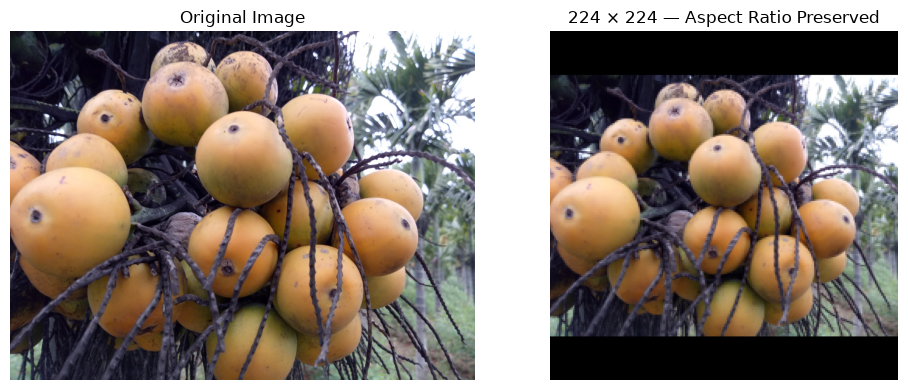

In [85]:

import matplotlib.pyplot as plt

sample_path = split_df[
    split_df["split"] == "train"
]["path"].iloc[0]

sample_image = cv2.imread(sample_path)

if sample_image is None:
    raise ValueError(f"Could not read image: {sample_path}")

sample_rgb = cv2.cvtColor(
    sample_image,
    cv2.COLOR_BGR2RGB
)

resized_image = resize_with_padding(sample_rgb, IMAGE_SIZE)

print("Original shape:", sample_rgb.shape)
print("Processed shape:", resized_image.shape)
print("Data type:", resized_image.dtype)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image)
plt.title("224 × 224 — Aspect Ratio Preserved")
plt.axis("off")

plt.tight_layout()
plt.show()


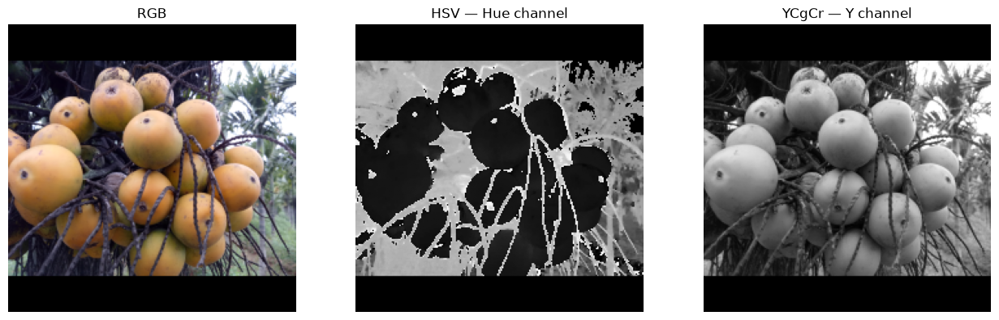

RGB shape: (224, 224, 3)
HSV shape: (224, 224, 3)
YCgCr shape: (224, 224, 3)
YCgCr minimum: -0.17843136
YCgCr maximum: 1.0


In [86]:

# RGB
rgb_image = resized_image.copy()

# HSV
hsv_image = cv2.cvtColor(
    rgb_image,
    cv2.COLOR_RGB2HSV
)

# YCgCr using the project's specified equations
rgb_float = rgb_image.astype(np.float32) / 255.0

R = rgb_float[:, :, 0]
G = rgb_float[:, :, 1]
B = rgb_float[:, :, 2]

Y = 0.25 * R + 0.50 * G + 0.25 * B
Cg = -0.25 * R + 0.50 * G - 0.25 * B
Cr = 0.50 * R - 0.50 * B

ycgcr_image = np.stack([Y, Cg, Cr], axis=-1)

# Display all three transformations
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(rgb_image)
axes[0].set_title("RGB")

axes[1].imshow(hsv_image[:, :, 0], cmap="gray")
axes[1].set_title("HSV — Hue channel")

axes[2].imshow(ycgcr_image[:, :, 0], cmap="gray")
axes[2].set_title("YCgCr — Y channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("RGB shape:", rgb_image.shape)
print("HSV shape:", hsv_image.shape)
print("YCgCr shape:", ycgcr_image.shape)

print("YCgCr minimum:", ycgcr_image.min())
print("YCgCr maximum:", ycgcr_image.max())


In [87]:

def inspect_channels(name, image):
    print(f"\n{name}")
    for i in range(image.shape[-1]):
        channel = image[:, :, i]
        print(
            f"Channel {i}: "
            f"min={channel.min():.4f}, "
            f"max={channel.max():.4f}, "
            f"mean={channel.mean():.4f}, "
            f"std={channel.std():.4f}"
        )

inspect_channels("RGB", rgb_image)
inspect_channels("HSV", hsv_image.astype(np.float32))
inspect_channels("YCgCr", ycgcr_image)



RGB
Channel 0: min=0.0000, max=255.0000, mean=91.5696, std=82.1565
Channel 1: min=0.0000, max=255.0000, mean=78.5429, std=71.8118
Channel 2: min=0.0000, max=255.0000, mean=68.8844, std=65.2416

HSV
Channel 0: min=0.0000, max=179.0000, mean=49.6300, std=55.6909
Channel 1: min=0.0000, max=255.0000, mean=71.1831, std=63.4468
Channel 2: min=0.0000, max=255.0000, mean=96.6508, std=82.2986

YCgCr
Channel 0: min=0.0000, max=1.0000, mean=0.3113, std=0.2795
Channel 1: min=-0.0539, max=0.0873, mean=-0.0033, std=0.0153
Channel 2: min=-0.1784, max=0.2824, mean=0.0445, std=0.0849


In [88]:

# RGB scaling
rgb_scaled = rgb_image.astype(np.float32) / 255.0

# HSV scaling
hsv_float = hsv_image.astype(np.float32)

hsv_scaled = np.stack([
    hsv_float[:, :, 0] / 179.0,
    hsv_float[:, :, 1] / 255.0,
    hsv_float[:, :, 2] / 255.0
], axis=-1)

# YCgCr scaling
ycgcr_scaled = ycgcr_image.copy().astype(np.float32)

ycgcr_scaled[:, :, 1] += 0.5
ycgcr_scaled[:, :, 2] += 0.5

# Inspect results
for name, image in [
    ("RGB", rgb_scaled),
    ("HSV", hsv_scaled),
    ("YCgCr", ycgcr_scaled)
]:
    print(f"\n{name}")
    print("Shape:", image.shape)
    print("Minimum:", image.min())
    print("Maximum:", image.max())
    print("Mean:", image.mean())
    print("Standard deviation:", image.std())



RGB
Shape: (224, 224, 3)
Minimum: 0.0
Maximum: 1.0
Mean: 0.31241426
Standard deviation: 0.29014567

HSV
Shape: (224, 224, 3)
Minimum: 0.0
Maximum: 1.0
Mean: 0.3118117
Standard deviation: 0.2998014

YCgCr
Shape: (224, 224, 3)
Minimum: 0.0
Maximum: 1.0
Mean: 0.45083067
Standard deviation: 0.19656646


In [89]:

from pathlib import Path

PROCESSED_DIR = Path("dataset/processed_dataset")

for color_space in COLOR_SPACES:
    for split in ["train", "validation", "test"]:
        for label in ["Ripe", "Unripe"]:
            folder = PROCESSED_DIR / color_space / split / label
            folder.mkdir(parents=True, exist_ok=True)

print("Directory structure created successfully.")

for color_space in COLOR_SPACES:
    print(f"\n{color_space}")
    for split in ["train", "validation", "test"]:
        print(f"  {split}: Ready")


Directory structure created successfully.

RGB
  train: Ready
  validation: Ready
  test: Ready

HSV
  train: Ready
  validation: Ready
  test: Ready

YCgCr
  train: Ready
  validation: Ready
  test: Ready


In [90]:

import cv2
import numpy as np
from pathlib import Path

def convert_color_space(rgb_image, color_space):
    if color_space == "RGB":
        return rgb_image.astype(np.float32) / 255.0

    elif color_space == "HSV":
        hsv = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2HSV)
        hsv = hsv.astype(np.float32)

        hsv[:, :, 0] /= 179.0
        hsv[:, :, 1] /= 255.0
        hsv[:, :, 2] /= 255.0

        return hsv

    elif color_space == "YCgCr":
        rgb = rgb_image.astype(np.float32) / 255.0

        R = rgb[:, :, 0]
        G = rgb[:, :, 1]
        B = rgb[:, :, 2]

        Y = 0.25 * R + 0.50 * G + 0.25 * B
        Cg = -0.25 * R + 0.50 * G - 0.25 * B
        Cr = 0.50 * R - 0.50 * B

        ycgcr = np.stack([Y, Cg + 0.5, Cr + 0.5], axis=-1)

        return ycgcr

    else:
        raise ValueError(f"Unsupported color space: {color_space}")


def preprocess_image(image_path, color_space):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    resized = resize_with_padding(rgb, IMAGE_SIZE)

    converted = convert_color_space(resized, color_space)

    if not np.isfinite(converted).all():
        raise ValueError(f"Non-finite values in {color_space}")

    if converted.min() < -1e-6 or converted.max() > 1.000001:
        raise ValueError(
            f"Values outside [0, 1] in {color_space}: "
            f"{converted.min()}, {converted.max()}"
        )

    return converted


In [91]:

# Select 2 images from each class in the training set
sample_df = (
    split_df[split_df["split"] == "train"]
    .groupby("class", group_keys=False)
    .head(2)
)

print("Selected sample images:")
display(sample_df[["filename", "class", "split"]])

# Process and save
for _, row in sample_df.iterrows():

    image_path = Path(row["path"])
    label = row["class"]

    for color_space in COLOR_SPACES:

        processed = preprocess_image(image_path, color_space)

        # Convert float [0, 1] to uint8 for PNG storage
        save_image = np.clip(
            processed * 255.0, 0, 255
        ).round().astype(np.uint8)

        output_path = (
            PROCESSED_DIR
            / color_space
            / "train"
            / label
            / f"{image_path.stem}.png"
        )

        success = cv2.imwrite(
            str(output_path),
            cv2.cvtColor(save_image, cv2.COLOR_RGB2BGR)
        )

        if not success:
            raise IOError(f"Could not save: {output_path}")

print("\nSample preprocessing completed.")

# Verify output files
for color_space in COLOR_SPACES:
    count = sum(
        1 for _ in (PROCESSED_DIR / color_space / "train").rglob("*.png")
    )
    print(f"{color_space}: {count} PNG files")


Selected sample images:


,filename,class,split
1,1.jpg,Ripe,train
3,100.jpg,Ripe,train
256,IP_UNRIP_001.jpg,Unripe,train
258,IP_UNRIP_004.jpg,Unripe,train



Sample preprocessing completed.
RGB: 4 PNG files
HSV: 4 PNG files
YCgCr: 4 PNG files


In [92]:

for color_space in COLOR_SPACES:

    print(f"\n--- {color_space} ---")

    for _, row in sample_df.iterrows():

        image_path = (
            PROCESSED_DIR
            / color_space
            / "train"
            / row["class"]
            / f"{Path(row['path']).stem}.png"
        )

        saved = cv2.imread(str(image_path))

        if saved is None:
            raise ValueError(f"Cannot reopen: {image_path}")

        saved = cv2.cvtColor(saved, cv2.COLOR_BGR2RGB)

        assert saved.shape == (224, 224, 3)
        assert saved.dtype == np.uint8

        print(
            f"{image_path.name}: "
            f"shape={saved.shape}, "
            f"range=({saved.min()}, {saved.max()})"
        )

print("\nAll saved sample images verified.")



--- RGB ---
1.png: shape=(224, 224, 3), range=(0, 255)
100.png: shape=(224, 224, 3), range=(0, 255)
IP_UNRIP_001.png: shape=(224, 224, 3), range=(0, 255)
IP_UNRIP_004.png: shape=(224, 224, 3), range=(0, 255)

--- HSV ---
1.png: shape=(224, 224, 3), range=(0, 255)
100.png: shape=(224, 224, 3), range=(0, 255)
IP_UNRIP_001.png: shape=(224, 224, 3), range=(0, 255)
IP_UNRIP_004.png: shape=(224, 224, 3), range=(0, 255)

--- YCgCr ---
1.png: shape=(224, 224, 3), range=(0, 255)
100.png: shape=(224, 224, 3), range=(0, 255)
IP_UNRIP_001.png: shape=(224, 224, 3), range=(0, 255)
IP_UNRIP_004.png: shape=(224, 224, 3), range=(0, 255)

All saved sample images verified.


In [93]:

from tqdm.auto import tqdm

processed_count = 0
failed_images = []

for _, row in tqdm(
    split_df.iterrows(),
    total=len(split_df),
    desc="Processing dataset"
):
    image_path = Path(row["path"])
    label = row["class"]
    split = row["split"]

    try:
        for color_space in COLOR_SPACES:

            processed = preprocess_image(
                image_path,
                color_space
            )

            save_image = np.clip(
                processed * 255.0,
                0,
                255
            ).round().astype(np.uint8)

            output_path = (
                PROCESSED_DIR
                / color_space
                / split
                / label
                / f"{image_path.stem}.png"
            )

            success = cv2.imwrite(
                str(output_path),
                cv2.cvtColor(
                    save_image,
                    cv2.COLOR_RGB2BGR
                )
            )

            if not success:
                raise IOError(f"Failed to save {output_path}")

        processed_count += 1

    except Exception as e:
        failed_images.append({
            "filename": image_path.name,
            "error": str(e)
        })

print("\nProcessing completed.")
print("Successfully processed:", processed_count)
print("Failed images:", len(failed_images))

if failed_images:
    display(pd.DataFrame(failed_images))


c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Processing dataset: 100%|██████████| 697/697 [03:01<00:00,  3.83it/s]


Processing completed.
Successfully processed: 697
Failed images: 0


In [94]:

# Expected counts from the frozen manifest
expected_counts = (
    split_df.groupby(["split", "class"])
    .size()
)

audit_results = []

for color_space in COLOR_SPACES:
    for (split, label), expected in expected_counts.items():

        folder = PROCESSED_DIR / color_space / split / label

        actual = len(list(folder.glob("*.png")))

        audit_results.append({
            "color_space": color_space,
            "split": split,
            "class": label,
            "expected": expected,
            "actual": actual,
            "match": actual == expected
        })

processed_audit = pd.DataFrame(audit_results)

display(processed_audit)

print("\nTotal processed PNG files:",
      processed_audit["actual"].sum())

print("All counts match:",
      processed_audit["match"].all())

assert processed_audit["match"].all()
assert processed_audit["actual"].sum() == 2091

print("\nFULL DATASET AUDIT PASSED")


,color_space,split,class,expected,actual,match
0,RGB,test,Ripe,26,26,True
1,RGB,test,Unripe,44,44,True
2,RGB,train,Ripe,204,204,True
3,RGB,train,Unripe,354,354,True
4,RGB,validation,Ripe,25,25,True
5,RGB,validation,Unripe,44,44,True
6,HSV,test,Ripe,26,26,True
7,HSV,test,Unripe,44,44,True
8,HSV,train,Ripe,204,204,True
9,HSV,train,Unripe,354,354,True



Total processed PNG files: 2091
All counts match: True

FULL DATASET AUDIT PASSED


In [95]:

import json

normalization_stats = {}

for color_space in COLOR_SPACES:

    channel_sum = np.zeros(3, dtype=np.float64)
    channel_squared_sum = np.zeros(3, dtype=np.float64)
    total_pixels = 0

    train_root = PROCESSED_DIR / color_space / "train"

    for label in ["Ripe", "Unripe"]:

        image_files = list(
            (train_root / label).glob("*.png")
        )

        for image_file in tqdm(
            image_files,
            desc=f"{color_space} - {label}"
        ):
            image = cv2.imread(str(image_file))

            if image is None:
                raise ValueError(f"Unreadable image: {image_file}")

            image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            ).astype(np.float64) / 255.0

            pixels = image.reshape(-1, 3)

            channel_sum += pixels.sum(axis=0)
            channel_squared_sum += (pixels ** 2).sum(axis=0)
            total_pixels += pixels.shape[0]

    mean = channel_sum / total_pixels

    variance = (
        channel_squared_sum / total_pixels
    ) - (mean ** 2)

    std = np.sqrt(np.maximum(variance, 0))

    normalization_stats[color_space] = {
        "mean": mean.tolist(),
        "std": std.tolist()
    }

    print(f"\n{color_space}")
    print("Mean:", mean)
    print("Std:", std)

# Save statistics
stats_path = PREPROCESSING_DIR / "normalization_stats.json"

with open(stats_path, "w") as f:
    json.dump(normalization_stats, f, indent=4)

print("\nNormalization statistics saved:", stats_path)


RGB - Unripe: 100%|██████████| 354/354 [00:00<00:00, 426.91it/s]



RGB
Mean: [0.34091837 0.31965236 0.24634765]
Std: [0.30734076 0.29907229 0.2818263 ]


HSV - Unripe: 100%|██████████| 354/354 [00:00<00:00, 427.22it/s]



HSV
Mean: [0.17910052 0.29213508 0.35356579]
Std: [0.23581773 0.28432642 0.31211639]


YCgCr - Unripe: 100%|██████████| 354/354 [00:00<00:00, 425.84it/s]


YCgCr
Mean: [0.30671704 0.51356824 0.54787686]
Std: [0.29169942 0.0264016  0.06957786]

Normalization statistics saved: research-notes\preprocessing\normalization_stats.json


In [96]:

import json

experiment_record = {
    "dataset_images": 697,
    "input_size": [224, 224],
    "splits": {
        "train": 558,
        "validation": 69,
        "test": 70
    },
    "color_spaces": COLOR_SPACES,
    "resize": "aspect_ratio_preserving_with_padding",
    "padding": "black",
    "storage": "PNG uint8",
    "normalization": normalization_stats,
    "random_seed": RANDOM_SEED,
    "augmentation": "not_applied_yet"
}

record_path = PREPROCESSING_DIR / "experiment_preprocessing_record.json"

with open(record_path, "w") as f:
    json.dump(experiment_record, f, indent=4)

print("Experiment record saved:", record_path)


Experiment record saved: research-notes\preprocessing\experiment_preprocessing_record.json


In [97]:

import torch
import torchvision
from torchvision.models import mobilenet_v2

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Verify ImageNet-pretrained MobileNetV2 weights are accessible
from torchvision.models import MobileNet_V2_Weights

print("MobileNetV2 ImageNet weights:", MobileNet_V2_Weights.DEFAULT)


PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
MobileNetV2 ImageNet weights: MobileNet_V2_Weights.IMAGENET1K_V2
